#ML Pipeline Alpha Test Part 1

Welcome to the alpha test for our ML pipeline, and thank you for participating. This is part 1 of a 3-part test. In this test, we are running 1 combined set of OSDR datasets (muscle data from 101, 103, 104, 105, 111) through a single pipeline configuration. It's meant to compare results from differential gene expression analysis (traditional statistical approach) to results from 2 ensembles of machine learning algorithms (traditional ML and causal ML). The objective of this "alpha" test is to see if the tables, graphs, and other output are what you would expect to see in this comparison, or if something is missing or shouldn't be included.

<b>Steps to run notebook:</b>

1. Click the "Run all" button (no need to change any configuration -- it's all set and ready to go).

2. Click through the google drive dialog boxes (3 total) that pop up after you get the notebook running to give this notebook permission to write output files to your google drive.

3. Scroll down to the last cell in the notebook (called "Run the experiment" and verify the notebook is running and making progress. You should see something like the following:
<pre style="font-family: 'Courier New', Courier, monospace; background-color: #000; color: #0df; padding: 10px; border-radius: 5px;">
[1/1] muscle_config_1   (OSD 101, 103, 104, 105, 111)
=======================================================
  Starting run on OSD 101, 103, 104, 105, 111 with random_forest, logistic_regression, xgboost, svm, neural_network
  Run id: 831969f9-05eb-4ede-8a66-8d47020e7483
  [  1%] starting: Pipeline started
  [  3%] downloading: Downloading 5 OSDR studies: OSD-101, OSD-103, OSD-104, OSD-105, OSD-111 (first time can take a while)...
  [ 15%] downloading: Downloaded 4 studies; combining...
</pre>

If you see an error, stop here and let me know what the error message is.

4. Keep the notebook open and running (but you can minimize the window). Set a timer for about 5 minutes (or just come back later) to see if it's finished.

5. Once the notebook is complete,  scroll to the last notebook cell ("Run the experiment" to look at the outputs and determine if they are informative for how DGEA compares/contrasts with ML in the analysis of controlled spaceflown muscle gene expression experiments. Note how long the notebook took from the output that looks like the following:
`Finished 1 of 1 runs without errors in 0:03:45`

6. Fill out this [brief survey](https://docs.google.com/forms/d/e/1FAIpQLSfs1x3utUtOGzQGZ9IQsoBUZVPG1QVfILtW0yu9M9lr2Ic70g/viewform?usp=publish-editor) to record your feedback.


<b>OPTIONAL #1</b>

If you want to run the notebook with different data, navigate to the "Datasets" section of this notebook and select one of the other sets by changing as shown below:

from
`DATASETS = {"muscle": muscle_osds}`

to
`DATASETS = {"liver": liver_osds}`

or to
`DATASETS = {"kidney": kidney_osds}`


<b>OPTIONAL #2</b>
If you want to explore the output on your google drive, navigate to `My Drive/NASA/FM/ML_PIPELINE` and check out the subdirectory created there named by the timestamp.


# Machine Learning Pipeline configurations

This notebook runs every configuration in `all_configs` on every dataset (muscle, liver, kidney) in one go, and saves
everything under a single timestamped folder:

```
<results root>/<YYYYMMDD_HHMMSS>/
    run_summary.csv              one row per run: accuracy, gene counts, overlap, GO terms, runtime, errors
    all_configs.json             the datasets and configurations used
    ML_ENSEMBLE_RESULTS/<dataset>_<config>/   metrics, plots, feature importance, consensus genes, mean vs variance
    DESEQ2_RESULTS/<dataset>_<config>/        all genes, significant genes, volcano plot, mean vs variance
    COMBO_RESULTS/<dataset>_<config>/         ML vs DESeq2 comparison, GO enrichment tables and plots
    COMBO_RESULTS/<dataset>_cross_config/     genes the configurations agree on, and GO enrichment on them
    cross_config_summary.csv     one row per dataset: agreed gene counts and GO terms
```

`ENRICHMENT_MODE` in the settings cell chooses when GO enrichment runs: for each run (`"per_run"`), once per
dataset after the loop on the genes found across configurations (`"cross_config"`), or both. Running it only
across configurations is faster and removes results that depend on one particular configuration.

The results root is your Google Drive (`MyDrive/NASA/FM/ML_PIPELINE`) when running in Colab, and
`ML_PIPELINE_RESULTS/` next to this notebook otherwise.

**To run:** check the datasets and configurations in the next two cells, then click **Run all**. In Colab you'll be asked
to allow access to Google Drive. The last cell runs one analysis after another and prints a summary table at the end.
Each run takes several minutes, so all 18 combinations take a while.

If the loop is interrupted, set `RESUME_TIMESTAMP` in the settings cell to the folder name it printed and run all
again: finished runs are skipped.

Settings you leave out of a configuration use the backend defaults:

| Setting | Default |
|---|---|
| `target_column`, `factor_name` | `Factor Value[Spaceflight]` |
| `factor_values` | `["Ground Control", "Space Flight"]` |
| `task_type` | `classification` |
| `trans_list` | `s,l` (standardize, log transform) |
| `ensemble_algorithms` | random_forest, logistic_regression, xgboost, svm, neural_network |
| `metrics` | accuracy, precision, recall, f1_score |
| `test_size` / `random_state` | 0.2 / 42 |
| `min_features` | 1000 |
| `fi_methods` | permutation, recursive |
| `convert_ensembl_to_symbol` / `coding_only` | True / True |
| `keep_biotypes` | protein_coding, lncRNA |
| `enrichment.ontologies` | `["BP"]` (also `"MF"`, `"CC"`) |
| `enrichment.methods` | ora, gsea |
| `enrichment.p_adjust_method` / `padj_cutoff` | BH / 0.05 |


## Dataset configurations

In [1]:
# OSD IDs analysed together for each dataset
muscle_osds = "101, 103, 104, 105, 111"

liver_osds = "47, 48, 137, 168"

kidney_osds = "462, 513, 771"

skin_osds = "237, 238, 239, 240, 241, 243"

DATASETS = {"muscle": muscle_osds}


## ML parameters

In [2]:
# Runtime configurations. The loop at the end runs each of these on each dataset.

all_configs = {
  "config_1" : {
          "ensemble_algorithms": ["random_forest", "logistic_regression", "xgboost", "svm", "neural_network"],
          "test_size": 0.3,
          "random_state": 42,
          "min_features": 500,
          "causal": {"enabled": True},
          "enrichment": {
              "enabled": True,
              "p_adjust_method": "BH",
              "ontologies": ["BP", "MF", "CC", "KEGG"],   # GO "BP", "MF", "CC"
          }
      },
  "config_2" : {
          "ensemble_algorithms": ["random_forest", "logistic_regression", "xgboost", "svm", "neural_network"],
          "test_size": 0.2,
          "random_state": 42,
          "min_features": 500,
          "causal": {"enabled": True},
          "enrichment": {
              "enabled": True,
              "p_adjust_method": "BH",
              "ontologies": ["BP", "MF", "CC", "KEGG"],   # GO "BP", "MF", "CC"
          }
      },
  "config_3" : {
          "ensemble_algorithms": ["random_forest", "logistic_regression", "xgboost", "svm", "neural_network"],
          "test_size": 0.2,
          "random_state": 41,
          "min_features": 500,
          "causal": {"enabled": True},
          "enrichment": {
              "enabled": True,
              "p_adjust_method": "BH",
              "ontologies": ["BP", "MF", "CC", "KEGG"],   # GO "BP", "MF", "CC"
          }
      },
  "config_4" : {
          "ensemble_algorithms": ["random_forest", "logistic_regression", "xgboost", "svm", "neural_network"],
          "test_size": 0.2,
          "random_state": 41,
          "min_features": 500,
          "causal": {"enabled": True},
          "enrichment": {
              "enabled": True,
              "p_adjust_method": "bonferroni",
              "ontologies": ["BP", "MF", "CC", "KEGG"],   # GO "BP", "MF", "CC"
          }
      },
  "config_5" : {
          "ensemble_algorithms": ["random_forest", "logistic_regression", "neural_network"],
          "test_size": 0.2,
          "random_state": 42,
          "min_features": 500,
          "causal": {"enabled": True},
          "enrichment": {
              "enabled": True,
              "p_adjust_method": "BH",
              "ontologies": ["BP", "MF", "CC", "KEGG"],   # GO "BP", "MF", "CC"
          }
      },
  "config_6" : {
          "ensemble_algorithms": ["random_forest", "logistic_regression", "neural_network"],
          "test_size": 0.3,
          "random_state": 42,
          "min_features": 500,
          "causal": {"enabled": True},
          "enrichment": {
              "enabled": True,
              "p_adjust_method": "BH",
              "ontologies": ["BP", "MF", "CC", "KEGG"],   # GO "BP", "MF", "CC"
          }
      }
}


# Every setting you leave out uses the backend default (see the table above).


## Pipeline parameters

In [3]:
# Backend
ORCHESTRATION_URL = "http://149.165.147.155:8000"

# Which runs: every dataset × every configuration by default
DATASETS_TO_RUN = list(DATASETS)          # e.g. ["kidney"]
CONFIGS_TO_RUN = ["config_1"]       # e.g. ["config_1", "config_4"]

# Where results go (a new timestamped folder is created inside)
DRIVE_RESULTS_ROOT = "/content/drive/MyDrive/NASA/FM/ML_PIPELINE"   # used in Google Colab
LOCAL_RESULTS_ROOT = "ML_PIPELINE_RESULTS"                          # used everywhere else
RESUME_TIMESTAMP = None    # e.g. "20261027_141500" to continue an interrupted loop; finished runs are skipped

# Analysis settings
PADJ_THRESHOLD = 0.05      # DESeq2 significance
LOG2FC_THRESHOLD = 2.0
TOP_N = 50                 # top genes per model for the consensus vote
MIN_VOTES = None           # None = simple majority of models
ML_GENE_SET = "significant"  # ML consensus genes: "significant" = significant (label-permutation test,
                             # fi_n_permutations in the config) in >= MIN_VOTES models, may be empty;
                             # "top_n" = in the top TOP_N of >= MIN_VOTES models (always ~TOP_N genes)
BOXPLOT_TOP_N = 10         # genes per box-plot figure (top ML consensus genes; top DESeq2 genes)
ENRICHMENT_TIMEOUT = (10, 1900)   # (connect, read) seconds; read is longer than the backend's 30 min limit

# GO enrichment: when to run it
#   "per_run"      for each run, using that run's genes (and its config's enrichment settings)
#   "cross_config" once per dataset after the loop, on the genes the configurations agree on
#   "both"
ENRICHMENT_MODE = "per_run"
CROSS_CONFIG_MIN_FRACTION = 1.0   # 1.0 = gene found in every run (strict intersection); 0.5 = in at least half
CROSS_CONFIG_ENRICHMENT = {"ontologies": ["BP", "MF", "CC", "KEGG"], "p_adjust_method": "BH"}   # rest = backend defaults

SHOW_PLOTS = True         # plots are always saved as PNG files; True also shows them here (about 10 per run)


# Functions

The cells below only define functions; nothing runs until the last cell.

### Environment and output folders

In [4]:
import json
import os
import re
import sys
import time
import traceback
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
RESULT_GROUPS = {"ml": "ML_ENSEMBLE_RESULTS", "deseq2": "DESEQ2_RESULTS", "combo": "COMBO_RESULTS",
                 "causal": "CAUSAL_RESULTS"}          # created only for runs with CRISP enabled
LAZY_GROUPS = {"causal"}

def results_root():
    """Google Drive folder in Colab (mounting Drive if needed), a local folder otherwise."""
    if IN_COLAB:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
        return Path(DRIVE_RESULTS_ROOT)
    return Path(LOCAL_RESULTS_ROOT).expanduser().resolve()


def make_timestamp_dir(timestamp=None):
    """<root>/<timestamp>/ with the three result folders. Reuses an existing timestamp to resume."""
    ts = timestamp or datetime.now().strftime("%Y%m%d_%H%M%S")
    root = results_root() / ts
    for key, group in RESULT_GROUPS.items():
        if key not in LAZY_GROUPS:
            (root / group).mkdir(parents=True, exist_ok=True)
    return root


def run_dirs(root, run_name):
    """{"ml": ..., "deseq2": ..., "combo": ...}: this run's folder inside each result folder."""
    dirs = {key: root / group / run_name for key, group in RESULT_GROUPS.items()}
    for key, d in dirs.items():
        if key not in LAZY_GROUPS:
            d.mkdir(parents=True, exist_ok=True)
    return dirs


def safe_name(s):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", str(s)).strip("_")


def finish_figure(fig, path):
    """Save a figure, show it if SHOW_PLOTS, and free it."""
    fig.savefig(path, dpi=150, bbox_inches="tight")
    if SHOW_PLOTS:
        plt.show()
    plt.close(fig)


def write_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str))


print("Running in Google Colab" if IN_COLAB else "Running locally")


Running in Google Colab


### Backend: defaults and pipeline runs

In [5]:
def get_defaults():
    """The backend's default configuration (all settings, including enrichment)."""
    r = requests.get(f"{ORCHESTRATION_URL}/api/config/defaults", timeout=10)
    r.raise_for_status()
    return r.json()


def build_payload(osd_ids, user_cfg, defaults):
    """Fill in every setting the configuration leaves out (enrichment merged key by key)."""
    cfg = {**defaults, **user_cfg,
           "enrichment": {**defaults.get("enrichment", {}), **user_cfg.get("enrichment", {})},
           "causal": {**defaults.get("causal", {}), **user_cfg.get("causal", {})}}
    return {"osd_ids": osd_ids, "config": cfg}


def _print_events(events):
    for ev in events:
        print(f"  [{ev.get('progress_percent', 0):3d}%] {ev.get('status', '')}: {ev.get('message', '')}")
        if ev.get("status") == "failed" and ev.get("error"):
            print(f"        error: {ev['error']}")


def wait_for_pipeline(pipeline_id, poll_seconds=10):
    """Follow a run until it finishes and return its result. Raises RuntimeError if it fails.
    Survives dropped connections: the run continues on the server meanwhile."""
    url = f"{ORCHESTRATION_URL}/api/pipeline/jobs/{pipeline_id}"
    since, failures = 0, 0
    while True:
        try:
            r = requests.get(url, params={"since": since}, timeout=30)
            if r.status_code == 404:
                raise RuntimeError(f"the backend doesn't know run {pipeline_id} (it was restarted, or the run expired)")
            r.raise_for_status()
            snap = r.json()
            if failures:
                print("  ...reconnected")
            failures = 0
        except requests.exceptions.RequestException as e:
            failures += 1
            wait = min(60, poll_seconds * 2 ** min(failures, 4))
            print(f"  (connection problem: {type(e).__name__}; retrying in {wait}s)")
            time.sleep(wait)
            continue

        _print_events(snap["events"])
        since = snap["next_since"]
        if snap["status"] == "completed":
            print(f"  ✓ Pipeline completed in {snap['elapsed_seconds'] // 60} min {snap['elapsed_seconds'] % 60} s")
            return snap["result"]
        if snap["status"] == "failed":
            raise RuntimeError(f"pipeline failed: {snap.get('error')}")
        time.sleep(poll_seconds)


def run_pipeline(payload):
    """Start a run on the backend and follow it to the end."""
    cfg = payload["config"]
    print(f"  Starting run on OSD {payload['osd_ids']} with {', '.join(cfg['ensemble_algorithms'])}")
    r = requests.post(f"{ORCHESTRATION_URL}/api/pipeline/jobs", json=payload, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"the backend rejected the request ({r.status_code}): {r.text[:500]}")
    pipeline_id = r.json()["pipeline_id"]
    print(f"  Run id: {pipeline_id}")
    return wait_for_pipeline(pipeline_id)


### ML ensemble: metrics, plots, consensus genes

For each model, genes are ranked by each feature-importance method the model supports (SVM has no RFE), and the method ranks are averaged. A gene gets one vote from each model that puts it in its top `TOP_N`. Consensus genes are those with votes from a simple majority of models (`MIN_VOTES`).

In [6]:
def ml_models(result):
    return result.get("training_results", {}).get("test_metrics", {}).get("models", [])


def ml_metrics_table(result):
    """One row per model, best test accuracy first.
    Accuracy..ROC_AUC are on the held-out test set; CV_* are k-fold CV on the training set."""
    rows = []
    for m in ml_models(result):
        cv = m.get("cv_metrics") or {}
        best = m.get("best_params") or {}
        rows.append({
            "Algorithm": m.get("algorithm", "unknown"),
            "Accuracy": m.get("accuracy", 0),
            "Precision": m.get("precision", 0),
            "Recall": m.get("recall", 0),
            "F1": m.get("f1_score", 0),
            "ROC_AUC": m.get("roc_auc"),
            "CV_Accuracy": cv.get("accuracy_mean"),
            "CV_Accuracy_SD": cv.get("accuracy_std"),
            "CV_F1": cv.get("f1_weighted_mean"),
            "CV_F1_SD": cv.get("f1_weighted_std"),
            "CV_ROC_AUC": cv.get("roc_auc_mean"),
            "CV_Folds": f"{int(cv['n_splits'])}x{int(cv['n_repeats'])}" if "n_splits" in cv else None,
            "Tuned": bool(m.get("tuned", False)),
            "Best_Params": "; ".join(f"{k}={v}" for k, v in sorted(best.items())) or None,
        })
    columns = ["Algorithm", "Accuracy", "Precision", "Recall", "F1", "ROC_AUC",
               "CV_Accuracy", "CV_Accuracy_SD", "CV_F1", "CV_F1_SD", "CV_ROC_AUC",
               "CV_Folds", "Tuned", "Best_Params"]
    df = pd.DataFrame(rows, columns=columns)
    return df.sort_values("Accuracy", ascending=False).reset_index(drop=True)


def plot_ml_performance(result, metrics, title, path):
    if metrics.empty:
        return
    mean_acc = result.get("training_results", {}).get("test_metrics", {}).get("mean_accuracy")
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"Ensemble model performance: {title}", fontsize=16, fontweight="bold")
    colors = plt.cm.Set3(np.linspace(0, 1, len(metrics)))
    for ax, col in zip(axes.ravel(), ["Accuracy", "Precision", "Recall", "F1"]):
        ax.bar(metrics["Algorithm"], metrics[col], color=colors, alpha=0.8)
        ax.set_title(col, fontsize=12, fontweight="bold")
        ax.set_ylabel("Score")
        ax.set_ylim([0, 1])
        ax.grid(axis="y", alpha=0.3)
        ax.tick_params(axis="x", rotation=45)
        if col == "Accuracy" and mean_acc is not None:
            ax.axhline(y=mean_acc, color="red", linestyle="--", label="Mean")
            ax.legend()
    fig.tight_layout()
    finish_figure(fig, path)


def plot_confusion_matrices(result, labels, title, path):
    """Confusion matrices returned by the ML service. Returns False if there are none."""
    from sklearn.metrics import ConfusionMatrixDisplay
    models = ml_models(result)
    matrices = {m.get("algorithm", f"model_{i}"): m["confusion_matrix"]
                for i, m in enumerate(models) if m.get("confusion_matrix") is not None}
    if not matrices:
        return False
    labels = next((m.get("labels") or m.get("class_labels") for m in models
                   if m.get("labels") or m.get("class_labels")), labels)
    n = len(matrices)
    ncols = min(3, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 4.0 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, cm) in zip(axes, matrices.items()):
        cm = np.asarray(cm)
        acc = np.trace(cm) / cm.sum() if cm.sum() else 0
        disp_labels = labels if labels and len(labels) == cm.shape[0] else None
        ConfusionMatrixDisplay(cm, display_labels=disp_labels).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d")
        ax.set_title(f"{name}\nacc {acc:.2f}  (n={int(cm.sum())})", fontsize=11)
        ax.tick_params(axis="x", labelrotation=20)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle(f"Confusion matrices on the held-out test set: {title}", fontsize=13, fontweight="bold")
    fig.tight_layout()
    finish_figure(fig, path)
    return True


def plot_feature_importance(fi_data, title, path, top=15):
    """Top genes by each importance method, for the first model."""
    if not fi_data:
        return
    model_id = next(iter(fi_data))
    methods = [m for m, v in fi_data[model_id].items() if (v or {}).get("features")][:2]
    if not methods:
        return
    fig, axes = plt.subplots(1, len(methods), figsize=(7 * len(methods), 6))
    axes = np.atleast_1d(axes)
    fig.suptitle(f"Feature importance: {model_id} ({title})", fontsize=14, fontweight="bold")
    for ax, method in zip(axes, methods):
        feats = sorted(fi_data[model_id][method]["features"], key=lambda f: f.get("importance", 0), reverse=True)[:top]
        ax.barh([f.get("feature_name", "?") for f in feats], [f.get("importance", 0) for f in feats],
                color="steelblue", alpha=0.8)
        ax.set_title(f"{method.capitalize()} importance (top {top})", fontweight="bold")
        ax.set_xlabel("Importance score")
        ax.invert_yaxis()
        ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    finish_figure(fig, path)


def model_rankings(fi_data):
    """{model_id: Series(gene -> mean rank across the model's importance methods)}"""
    out = {}
    for model_id, methods in fi_data.items():
        ranks = []
        for method, data in methods.items():
            feats = (data or {}).get("features", [])
            if not feats:
                continue
            df = pd.DataFrame(feats)
            if "rank" in df and df["rank"].notna().all() and df["rank"].nunique() > 1:
                r = df.set_index("feature_name")["rank"].astype(float)
            else:
                r = df.set_index("feature_name")["importance"].rank(ascending=False, method="min")
            ranks.append(r.rename(method))
        if ranks:
            out[model_id] = pd.concat(ranks, axis=1).mean(axis=1).sort_values()
    return out


def consensus_genes_from(rankings, top_n=TOP_N, min_votes=MIN_VOTES):
    """Each model votes for its top_n genes; consensus = genes with at least min_votes votes.
    Returns (all genes with votes, consensus genes, min_votes used)."""
    min_votes = min_votes or (len(rankings) // 2 + 1)
    top_sets = [set(r.index[:top_n]) for r in rankings.values()]
    votes = pd.Series([g for s in top_sets for g in s]).value_counts()
    mean_rank = pd.concat(rankings.values(), axis=1).mean(axis=1)
    votes_df = (pd.DataFrame({"gene": votes.index, "votes": votes.values})
                .assign(mean_rank=lambda d: d["gene"].map(mean_rank).round(1))
                .sort_values(["votes", "mean_rank"], ascending=[False, True])
                .reset_index(drop=True))
    return votes_df, votes_df[votes_df["votes"] >= min_votes], min_votes


def model_significance(fi_data, models=None):
    """{model_id: DataFrame(gene, importance, pvalue, padj, significant)} from the permutation method's
    label-permutation test; {} when the test didn't run (fi_n_permutations = 0, or models from before it)."""
    algo = {m.get("model_id"): m.get("algorithm") for m in (models or [])}
    out = {}
    for model_id, methods in (fi_data or {}).items():
        feats = ((methods or {}).get("permutation") or {}).get("features") or []
        if feats and "pvalue" in feats[0]:
            t = pd.DataFrame(feats).rename(columns={"feature_name": "gene"})
            t["significant"] = t["significant"].astype(bool)
            t.insert(0, "algorithm", algo.get(model_id, model_id))
            out[model_id] = t[["algorithm", "gene", "importance", "pvalue", "padj", "significant"]]
    return out


def significance_consensus(sig_tables, rankings, min_votes=MIN_VOTES):
    """Each model votes for the genes significant in its permutation test; consensus = genes with at
    least min_votes votes (default: a majority of models). Same columns as consensus_genes_from, so
    everything downstream is unchanged. The consensus can be empty."""
    min_votes = min_votes or (len(sig_tables) // 2 + 1)
    votes = pd.Series([g for t in sig_tables.values() for g in t.loc[t["significant"], "gene"]],
                      dtype=object).value_counts()
    mean_rank = pd.concat(rankings.values(), axis=1).mean(axis=1) if rankings else pd.Series(dtype=float)
    votes_df = (pd.DataFrame({"gene": votes.index.astype(str), "votes": votes.values.astype(int)})
                .assign(mean_rank=lambda d: d["gene"].map(mean_rank).round(1))
                .sort_values(["votes", "mean_rank"], ascending=[False, True])
                .reset_index(drop=True))
    return votes_df, votes_df[votes_df["votes"] >= min_votes], min_votes


def save_ml_results(result, metrics, rankings, votes_df, consensus, out_dir):
    ml_part = {k: v for k, v in result.items() if k != "deseq2_results"}
    write_json(ml_part, out_dir / "ml_results.json")
    metrics.to_csv(out_dir / "ensemble_metrics.csv", index=False)
    if rankings:
        (pd.DataFrame(rankings).rename_axis("gene").sort_values(list(rankings)[0])
         .to_csv(out_dir / "gene_mean_rank_per_model.csv"))
    if votes_df is not None:
        votes_df.to_csv(out_dir / "consensus_gene_votes.csv", index=False)
    if consensus is not None:
        consensus.to_csv(out_dir / "consensus_genes.csv", index=False)    # read back by the cross-config step


### DESeq2

In [7]:
def deseq2_table(result):
    """All genes DESeq2 returned, as a DataFrame (None if DESeq2 failed)."""
    deseq2 = result.get("deseq2_results", {}) or {}
    if not deseq2.get("success"):
        return None
    df = pd.DataFrame(deseq2.get("differential_genes", []))
    if df.empty:
        return df
    df["gene_id"] = df["gene_id"].astype(str)
    return df


def deseq2_significant(deseq2_df, padj=PADJ_THRESHOLD, lfc=LOG2FC_THRESHOLD):
    return deseq2_df[(deseq2_df["padj"] < padj) & (deseq2_df["log2_fold_change"].abs() > lfc)]


def plot_volcano(deseq2_df, title, path, padj=PADJ_THRESHOLD, lfc=LOG2FC_THRESHOLD):
    if deseq2_df is None or deseq2_df.empty:
        return
    sig = (deseq2_df["padj"] < padj) & (deseq2_df["log2_fold_change"].abs() > lfc)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(deseq2_df["log2_fold_change"], -np.log10(deseq2_df["pvalue"].astype(float).clip(lower=1e-300)),
               c=np.where(sig, "red", "gray"), alpha=0.6, s=30)
    ax.axvline(x=lfc, color="blue", linestyle="--", alpha=0.5, label="Log2FC threshold")
    ax.axvline(x=-lfc, color="blue", linestyle="--", alpha=0.5)
    ax.axhline(y=-np.log10(padj), color="green", linestyle="--", alpha=0.5, label="P threshold")
    ax.set_xlabel("Log2 fold change")
    ax.set_ylabel("-Log10 p-value")
    ax.set_title(f"Volcano plot: DESeq2 ({title}), {int(sig.sum())} significant genes")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    finish_figure(fig, path)


def save_deseq2_results(result, deseq2_df, out_dir, padj=PADJ_THRESHOLD, lfc=LOG2FC_THRESHOLD):
    deseq2 = result.get("deseq2_results", {}) or {}
    summary = {k: v for k, v in deseq2.items() if k != "differential_genes"}
    summary.update({"padj_threshold": padj, "log2fc_threshold": lfc,
                    "n_returned": 0 if deseq2_df is None else len(deseq2_df),
                    "n_significant_at_thresholds": 0 if deseq2_df is None or deseq2_df.empty
                    else len(deseq2_significant(deseq2_df, padj, lfc))})
    write_json(summary, out_dir / "deseq2_summary.json")
    if deseq2_df is not None and not deseq2_df.empty:
        deseq2_df.sort_values("padj").to_csv(out_dir / "deseq2_all_genes.csv", index=False)
        deseq2_significant(deseq2_df, padj, lfc).sort_values("padj").to_csv(
            out_dir / "deseq2_significant_genes.csv", index=False)
    return summary


### CRISP causal code

In [8]:
from scipy.stats import hypergeom

CRISP_UP, CRISP_DOWN = "#c0392b", "#2471a3"      # same colours as the GSEA plots: higher / lower with the 2nd factor value


def crisp_results(result):
    """The CRISP block of a pipeline result ({} if CRISP wasn't enabled)."""
    return result.get("causal_results") or {}


def crisp_ranking_table(crisp):
    """Ranked genes: gene, rank, score, votes, n_methods, consensus, log2fc, direction, consistent,
    significant (in ICP's or NLICP's formal result), significant_in."""
    t = pd.DataFrame(crisp.get("ranking") or [],
                     columns=["gene", "rank", "score", "votes", "n_methods", "consensus", "log2fc",
                              "direction", "consistent", "significant", "significant_in"])
    t["significant"] = t["significant"].fillna(False).astype(bool)     # results from before this change
    t["significant_in"] = t["significant_in"].fillna("")
    return t


def crisp_selected(ranking, cfg):
    """CRISP's gene set, by causal.gene_set:
      "significant" (default): genes in ICP's or NLICP's formal result; may be empty, like DESeq2
      "consensus": votes >= causal.min_votes, or (min_votes 0) a majority of the methods."""
    if ranking is None or ranking.empty:
        return ranking.iloc[0:0] if ranking is not None else None
    causal = cfg.get("causal") or {}
    if causal.get("gene_set", "significant") == "significant":
        keep = ranking["significant"].astype(bool)
    else:
        min_votes = causal.get("min_votes") or 0
        keep = ranking["votes"] >= min_votes if min_votes else ranking["consensus"].astype(bool)
    return ranking[keep].sort_values("rank")


def save_crisp_results(crisp, ranking, selected, out_dir):
    ranking.to_csv(out_dir / "crisp_ranking.csv", index=False)
    selected.to_csv(out_dir / "crisp_genes.csv", index=False)
    methods = pd.DataFrame([{**{k: m.get(k) for k in ("method", "code", "causal", "selection", "n_tested_subsets",
                                                      "n_accepted_subsets", "test_acc", "val_acc", "note")},
                             "n_features": len(m.get("features", []))} for m in crisp.get("methods", [])])
    methods.to_csv(out_dir / "crisp_methods.csv", index=False)
    coefs = pd.DataFrame([{"method": m["code"], "gene": g, "coefficient": c,
                           "pval": (m["pvals"][i] if len(m.get("pvals") or []) == len(m["features"]) else None)}
                          for m in crisp.get("methods", []) if m.get("coefficients")
                          for i, (g, c) in enumerate(zip(m["features"], m["coefficients"]))])
    coefs.to_csv(out_dir / "crisp_coefficients.csv", index=False)
    pd.DataFrame(crisp.get("environments", [])).to_csv(out_dir / "crisp_environments.csv", index=False)
    write_json({k: v for k, v in crisp.items() if k not in ("methods", "ranking")}, out_dir / "crisp_summary.json")


def plot_crisp_ranking(ranking, factor_values, title, path, top=25):
    """Top genes by CRISP score; bar colour = direction, label = votes. Hatched = the direction
    is not the same in every study. ★ = significant (in ICP's or NLICP's formal result)."""
    if ranking is None or ranking.empty:
        return False
    d = ranking.sort_values("rank").head(top).iloc[::-1]
    fl = factor_values or ["control", "treatment"]
    fig, ax = plt.subplots(figsize=(9, max(3, 0.32 * len(d) + 1.4)))
    colors = [CRISP_UP if v > 0 else CRISP_DOWN for v in d["direction"]]
    labels = [f"★ {g}" if s else g for g, s in zip(d["gene"], d["significant"])]
    bars = ax.barh(labels, d["score"], color=colors, height=0.7)
    for b, cons in zip(bars, d["consistent"]):
        if not cons:
            b.set_hatch("///"); b.set_edgecolor("white")
    for b, v, n in zip(bars, d["votes"], d["n_methods"]):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f" {v}/{n}", va="center", fontsize=8, color="#52514e")
    ax.set_xlabel("CRISP score (mean scaled importance across methods); label = methods voting")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=CRISP_UP, label=f"higher in {fl[-1]}"), Patch(color=CRISP_DOWN, label=f"higher in {fl[0]}"),
                       Patch(facecolor="#898781", hatch="///", edgecolor="white", label="direction differs between studies")],
              frameon=False, fontsize=8, loc="lower right")
    n_sig = int(ranking["significant"].sum())
    ax.set_title(f"CRISP gene ranking: {title}\n★ = significant in ICP/NLICP ({n_sig} gene{'s' if n_sig != 1 else ''})",
                 fontweight="bold", fontsize=10)
    ax.grid(axis="x", alpha=0.3)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    finish_figure(fig, path)
    return True


def plot_crisp_methods(crisp, title, path):
    """Held-out accuracy of each CRISP method (CRISP's own split; baselines in grey)."""
    m = [x for x in crisp.get("methods", []) if x.get("test_acc") is not None]
    if not m:
        return False
    fig, ax = plt.subplots(figsize=(8, 3.6))
    names = [f"{x['code']}" + ("" if x["coefficients"] or not x["causal"] else "\n(no solution)") for x in m]
    ax.bar(names, [x["test_acc"] for x in m], color=["#2a78d6" if x["causal"] else "#c3c2b7" for x in m])
    ax.set_ylim(0, 1)
    ax.set_ylabel("test accuracy")
    ax.set_title(f"CRISP methods (blue = causal, grey = baseline / feature reduction): {title}", fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    finish_figure(fig, path)
    return True


def three_way_overlap(ml_genes, deseq2_genes, crisp_genes, universe):
    """Genes in each combination of ML consensus / DESeq2 significant / CRISP, plus hypergeometric
    p-values for CRISP vs each of the other two (is the overlap larger than chance?)."""
    U = {str(g) for g in universe}
    sets = {"ML": {str(g) for g in ml_genes} & U, "DESeq2": {str(g) for g in deseq2_genes} & U,
            "CRISP": {str(g) for g in crisp_genes} & U}
    allg = sorted(set().union(*sets.values()))
    table = pd.DataFrame({"gene": allg})
    for k, s in sets.items():
        table[f"in_{k}"] = table["gene"].isin(s)
    table["sets"] = table.apply(lambda r: " + ".join(k for k in sets if r[f"in_{k}"]), axis=1)
    N = len(U)

    def hyper(a, b):
        k, n, K = len(sets[a] & sets[b]), len(sets[a]), len(sets[b])
        return {"overlap": k, "expected": round(n * K / N, 2) if N else 0,
                "p": float(hypergeom.sf(k - 1, N, K, n)) if N and n and K else 1.0}

    stats = {"CRISP_vs_ML": hyper("CRISP", "ML"), "CRISP_vs_DESeq2": hyper("CRISP", "DESeq2"),
             "ML_vs_DESeq2": hyper("ML", "DESeq2"), "n_universe": N,
             "sizes": {k: len(v) for k, v in sets.items()}, "all_three": sorted(set.intersection(*sets.values()))}
    return table, stats


def plot_three_way(table, stats, title, path):
    if table.empty:
        return False
    counts = table["sets"].value_counts()
    order = ["ML + DESeq2 + CRISP", "ML + CRISP", "DESeq2 + CRISP", "ML + DESeq2", "CRISP", "ML", "DESeq2"]
    counts = counts.reindex([o for o in order if o in counts.index])
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(counts.index[::-1], counts.values[::-1], color=["#6250d6" if "CRISP" in i else "#c3c2b7" for i in counts.index[::-1]])
    for i, v in enumerate(counts.values[::-1]):
        ax.text(v, i, f" {v}", va="center", fontsize=9)
    s = stats
    ax.set_xlabel("genes")
    ax.set_title(f"ML consensus / DESeq2 / CRISP: {title}\n"
                 f"CRISP∩ML {s['CRISP_vs_ML']['overlap']} (exp. {s['CRISP_vs_ML']['expected']}, p={s['CRISP_vs_ML']['p']:.2g}) · "
                 f"CRISP∩DESeq2 {s['CRISP_vs_DESeq2']['overlap']} (exp. {s['CRISP_vs_DESeq2']['expected']}, "
                 f"p={s['CRISP_vs_DESeq2']['p']:.2g})", fontsize=10)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    fig.tight_layout()
    finish_figure(fig, path)
    return True


def plot_volcano_three_way(deseq2_df, ml_genes, crisp_genes, factor_values, title, path,
                           padj=PADJ_THRESHOLD, lfc=LOG2FC_THRESHOLD, max_labels=25):
    """DESeq2 volcano with the ML consensus genes (orange rings) and CRISP genes (purple diamonds)
    marked. Genes found by at least two of the three approaches are labelled."""
    v = deseq2_df.copy()
    v["gene"] = v["gene_id"].astype(str)
    v["neglog10_padj"] = -np.log10(v["padj"].astype(float).fillna(1).clip(lower=1e-300))
    sig = (v["padj"] < padj) & (v["log2_fold_change"].abs() > lfc)
    ml, cr = {str(g) for g in ml_genes}, {str(g) for g in crisp_genes}
    in_ml, in_cr = v["gene"].isin(ml), v["gene"].isin(cr)

    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.scatter(v.loc[~sig, "log2_fold_change"], v.loc[~sig, "neglog10_padj"], s=10, color="#c3c2b7",
               edgecolor="none", label=f"Not significant ({int((~sig).sum())})")
    ax.scatter(v.loc[sig, "log2_fold_change"], v.loc[sig, "neglog10_padj"], s=16, color="#2a78d6",
               edgecolor="none", label=f"DESeq2 significant ({int(sig.sum())})")
    ax.scatter(v.loc[in_ml, "log2_fold_change"], v.loc[in_ml, "neglog10_padj"], s=70, facecolor="none",
               edgecolor="#eb6834", linewidth=1.6, label=f"ML consensus ({int(in_ml.sum())})")
    ax.scatter(v.loc[in_cr, "log2_fold_change"], v.loc[in_cr, "neglog10_padj"], s=46, marker="D",
               facecolor="none", edgecolor="#6250d6", linewidth=1.6, label=f"CRISP ({int(in_cr.sum())})")

    n_found = sig.astype(int) + in_ml.astype(int) + in_cr.astype(int)
    for _, r in v[n_found >= 2].nlargest(max_labels, "neglog10_padj").iterrows():
        ax.annotate(r["gene"], (r["log2_fold_change"], r["neglog10_padj"]), fontsize=8,
                    xytext=(4, 3), textcoords="offset points")
    ax.axhline(-np.log10(padj), ls="--", lw=0.8, color="#898781")
    for x in (lfc, -lfc):
        ax.axvline(x, ls="--", lw=0.8, color="#898781")
    fl = factor_values or ["control", "treatment"]
    ax.set_xlabel(f"log2 fold change ({fl[-1]} vs {fl[0]})")
    ax.set_ylabel("-log10 adjusted p")
    all3 = int((sig & in_ml & in_cr).sum())
    ax.set_title(f"DESeq2 with ML consensus and CRISP genes ({title}); found by all three: {all3}",
                 fontweight="bold")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    finish_figure(fig, path)


### ML consensus genes vs DESeq2

In [9]:
# Compare the ML ensemble's consensus genes with DESeq2's differentially expressed genes.
# The hypergeometric p-value asks how likely an overlap this large would be if the consensus genes
# were a random draw from the tested genes.
import logging
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Union

import pandas as pd
from scipy.stats import hypergeom

logger = logging.getLogger("gene_comparison")

_GENE_COLS = ["gene", "gene_id", "gene_symbol", "symbol", "feature", "feature_name", "name"]
_LFC_COLS = ["log2FoldChange", "log2_fold_change", "log2fc", "l2fc", "lfc"]
_PADJ_COLS = ["padj", "p_adj", "adj_pvalue", "fdr", "qvalue"]
_SCORE_COLS = ["votes", "vote_count", "n_models", "score", "importance", "mean_importance", "consensus_score"]


def _find_col(df: pd.DataFrame, candidates: List[str], required: bool = True) -> Optional[str]:
    lower = {c.lower(): c for c in df.columns}
    for cand in candidates:
        if cand.lower() in lower:
            return lower[cand.lower()]
    if required:
        raise ValueError(f"None of {candidates} found in columns {list(df.columns)}")
    return None


def _normalize_consensus(consensus) -> pd.DataFrame:
    """Return DataFrame[gene, ml_score, ml_rank]."""
    if isinstance(consensus, pd.DataFrame):
        df = consensus.copy()
        gcol = _find_col(df, _GENE_COLS, required=False)
        if gcol is None:  # gene names may be the index
            df = df.reset_index().rename(columns={"index": "gene"})
            gcol = "gene"
        scol = _find_col(df, _SCORE_COLS, required=False)
        out = pd.DataFrame({"gene": df[gcol].astype(str)})
        out["ml_score"] = df[scol].values if scol else range(len(df), 0, -1)
    elif isinstance(consensus, dict):
        out = pd.DataFrame({"gene": [str(g) for g in consensus], "ml_score": list(consensus.values())})
    else:  # ordered iterable, most important first
        genes = [str(g) for g in consensus]
        out = pd.DataFrame({"gene": genes, "ml_score": range(len(genes), 0, -1)})

    out = out.drop_duplicates("gene").sort_values("ml_score", ascending=False).reset_index(drop=True)
    out["ml_rank"] = range(1, len(out) + 1)
    return out


def _normalize_deseq2(deseq2_results) -> pd.DataFrame:
    """Return DataFrame[gene, log2FoldChange, padj] for all tested genes."""
    df = pd.DataFrame(deseq2_results).copy()
    gcol = _find_col(df, _GENE_COLS, required=False)
    if gcol is None:
        df = df.reset_index().rename(columns={"index": "gene"})
        gcol = "gene"
    lfc = _find_col(df, _LFC_COLS)
    padj = _find_col(df, _PADJ_COLS)
    out = pd.DataFrame({
        "gene": df[gcol].astype(str),
        "log2FoldChange": pd.to_numeric(df[lfc], errors="coerce"),
        "padj": pd.to_numeric(df[padj], errors="coerce"),
    })
    return out.drop_duplicates("gene").reset_index(drop=True)


def compare_genes(
    consensus_genes: Union[List[str], Dict[str, float], pd.DataFrame],
    deseq2_results: Union[pd.DataFrame, List[dict]],
    universe: Optional[Iterable[str]] = None,
    padj_threshold: float = 0.05,
    log2fc_threshold: float = 2.0,
    top_n_ml: Optional[int] = None,
    output_dir: Optional[Union[str, Path]] = None,
) -> Dict:
    """
    Compare ML consensus genes with DESeq2 significant genes.

    Returns a dict with:
      overlap, ml_only, deseq2_only : sorted gene lists
      n_ml, n_deseq2, n_overlap, n_universe
      jaccard                       : |A∩B| / |A∪B|
      hypergeom_pvalue              : P(overlap >= observed) by chance
      expected_overlap              : overlap expected by chance
      fold_enrichment               : observed / expected
      table                         : DataFrame, one row per gene in either set
    """
    ml = _normalize_consensus(consensus_genes)
    if top_n_ml is not None:
        ml = ml.head(top_n_ml)
    de = _normalize_deseq2(deseq2_results)

    sig_mask = (de["padj"] < padj_threshold) & (de["log2FoldChange"].abs() > log2fc_threshold)
    deg = de[sig_mask]

    ml_set = set(ml["gene"])
    deg_set = set(deg["gene"])

    if universe is not None:
        universe_set = {str(g) for g in universe}
    else:
        universe_set = set(de["gene"]) | ml_set
        logger.warning("No gene universe supplied; using DESeq2-tested genes ∪ ML genes "
                       f"({len(universe_set)} genes) for the enrichment test.")

    # Genes outside the universe can't be tested; drop them from both sets
    dropped = (ml_set | deg_set) - universe_set
    if dropped:
        logger.warning(f"{len(dropped)} genes not in universe were ignored: {sorted(dropped)[:10]}...")
    ml_set &= universe_set
    deg_set &= universe_set

    overlap = ml_set & deg_set
    union = ml_set | deg_set
    N, K, n, k = len(universe_set), len(deg_set), len(ml_set), len(overlap)

    expected = (n * K / N) if N else 0.0
    pval = float(hypergeom.sf(k - 1, N, K, n)) if N and n and K else 1.0
    jaccard = (k / len(union)) if union else 0.0
    fold = (k / expected) if expected > 0 else float("nan")

    # Merged per-gene table
    table = pd.DataFrame({"gene": sorted(union)})
    table = table.merge(ml[["gene", "ml_rank", "ml_score"]], on="gene", how="left")
    table = table.merge(de, on="gene", how="left")
    table["in_ml"] = table["gene"].isin(ml_set)
    table["in_deseq2"] = table["gene"].isin(deg_set)
    table["category"] = table.apply(
        lambda r: "both" if r.in_ml and r.in_deseq2 else ("ml_only" if r.in_ml else "deseq2_only"), axis=1
    )
    table["direction"] = table["log2FoldChange"].apply(
        lambda x: "up" if pd.notna(x) and x > 0 else ("down" if pd.notna(x) and x < 0 else "")
    )
    cat_order = {"both": 0, "ml_only": 1, "deseq2_only": 2}
    table = table.sort_values(
        by=["category", "ml_rank", "padj"],
        key=lambda s: s.map(cat_order) if s.name == "category" else s,
        na_position="last",
    ).reset_index(drop=True)

    result = {
        "overlap": sorted(overlap),
        "ml_only": sorted(ml_set - deg_set),
        "deseq2_only": sorted(deg_set - ml_set),
        "n_ml": n,
        "n_deseq2": K,
        "n_overlap": k,
        "n_universe": N,
        "jaccard": round(jaccard, 4),
        "expected_overlap": round(expected, 3),
        "fold_enrichment": round(fold, 3) if fold == fold else None,
        "hypergeom_pvalue": pval,
        "padj_threshold": padj_threshold,
        "log2fc_threshold": log2fc_threshold,
        "table": table,
    }

    logger.info(
        f"Gene comparison: ML={n}, DESeq2={K}, overlap={k} "
        f"(expected {expected:.2f}, p={pval:.3g}, Jaccard={jaccard:.3f})"
    )

    if output_dir is not None:
        out = Path(output_dir)
        out.mkdir(parents=True, exist_ok=True)
        table.to_csv(out / "gene_comparison.csv", index=False)
        summary = {k_: v for k_, v in result.items() if k_ != "table"}
        pd.Series(summary).to_json(out / "gene_comparison_summary.json", indent=2)
        logger.info(f"Saved gene comparison to {out}")

    return result


### Combined results: comparison plot and GO enrichment

- **ORA (over-representation)** asks whether a gene list (ML consensus, DESeq2 significant, their overlap) contains more genes from a GO term than expected by chance.
- **GSEA** uses every gene, ranked: DESeq2 by direction and strength of change (signed −log10 p), and the ML ensemble by mean importance rank.

The background is the set of genes the pipeline analysed (the CV-filtered genes), not the whole genome.

In [10]:
def plot_combo_volcano(deseq2_df, cmp, factor_values, title, path, padj=PADJ_THRESHOLD, lfc=LOG2FC_THRESHOLD):
    """DESeq2 volcano with ML consensus genes highlighted."""
    v = deseq2_df.copy()
    v["gene"] = v["gene_id"].astype(str)
    v["category"] = v["gene"].map(cmp["table"].set_index("gene")["category"]).fillna("neither")
    v["neglog10_padj"] = -np.log10(v["padj"].astype(float).clip(lower=1e-300))
    style = {
        "neither":     dict(color="#c4c4c4", s=12, label="Neither"),
        "deseq2_only": dict(color="#4c78a8", s=20, label="DESeq2 only"),
        "ml_only":     dict(color="#f58518", s=24, label="ML consensus only"),
        "both":        dict(color="#d62728", s=44, label="Both"),
    }
    fig, ax = plt.subplots(figsize=(10, 6.5))
    for c, kw in style.items():
        sub = v[v["category"] == c]
        if len(sub):
            kw = dict(kw)
            ax.scatter(sub["log2_fold_change"], sub["neglog10_padj"], alpha=0.85, edgecolor="none",
                       label=f"{kw.pop('label')} ({len(sub)})", **kw)
    for _, r in v[v["category"] == "both"].nlargest(20, "neglog10_padj").iterrows():
        ax.annotate(r["gene"], (r["log2_fold_change"], r["neglog10_padj"]), fontsize=8,
                    xytext=(3, 3), textcoords="offset points")
    ax.axhline(-np.log10(padj), ls="--", lw=0.8, color="green")
    ax.axvline(x=lfc, color="blue", linestyle="--", alpha=0.5)
    ax.axvline(x=-lfc, color="blue", linestyle="--", alpha=0.5)
    fl = factor_values or ["control", "treatment"]
    ax.set_xlabel(f"log2 fold change ({fl[-1]} vs {fl[0]})")
    ax.set_ylabel("-log10 adjusted p")
    ax.set_title(f"DESeq2 results with ML consensus genes highlighted ({title})", fontweight="bold")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    finish_figure(fig, path)


def save_comparison(cmp, out_dir):
    cmp["table"].to_csv(out_dir / "gene_comparison.csv", index=False)
    write_json({k: v for k, v in cmp.items() if k != "table"}, out_dir / "gene_comparison_summary.json")


# ── GO enrichment ─────────────────────────────────────────────────────────────

def build_enrichment_inputs(deseq2_df, consensus_genes, rankings, cmp,
                            padj=PADJ_THRESHOLD, lfc=LOG2FC_THRESHOLD, crisp_genes=None):

    """Gene lists (ORA), rankings (GSEA) and background genes for one run.
    Returns (lists, rankings, universe, notes)."""
    notes, lists, ranks = [], {}, {}
    de = deseq2_df if deseq2_df is not None and not deseq2_df.empty else None

    if de is not None:
        sig = deseq2_significant(de, padj, lfc)
        lists["deseq2_significant"] = sig["gene_id"].tolist()
        lists["deseq2_up"] = sig.loc[sig["log2_fold_change"] > 0, "gene_id"].tolist()
        lists["deseq2_down"] = sig.loc[sig["log2_fold_change"] < 0, "gene_id"].tolist()
        p = de["pvalue"].astype(float).clip(lower=1e-300)
        signed = np.sign(de["log2_fold_change"].astype(float)) * -np.log10(p)
        ok = np.isfinite(signed)
        ranks["deseq2"] = {"scores": dict(zip(de.loc[ok, "gene_id"], signed[ok].astype(float))), "score_type": "std"}
    else:
        notes.append("no DESeq2 results: skipping DESeq2 lists and ranking")

    if consensus_genes is not None:
        lists["ml_consensus"] = consensus_genes["gene"].astype(str).tolist()
    else:
        notes.append("no ML consensus genes")
    if rankings:
        mean_rank = pd.concat(rankings.values(), axis=1).mean(axis=1).dropna()
        n = len(mean_rank)
        score = (n - mean_rank + 1) / n                     # best gene ~1, worst ~0; all positive
        ranks["ml_importance"] = {"scores": {str(g): float(s) for g, s in score.items()}, "score_type": "pos"}

    if crisp_genes is not None and len(crisp_genes):
        lists["crisp_invariant"] = [str(g) for g in crisp_genes]
        if "ml_consensus" in lists:
            lists["crisp_ml_overlap"] = sorted(set(lists["crisp_invariant"]) & set(lists["ml_consensus"]))
        if "deseq2_significant" in lists:
            lists["crisp_deseq2_overlap"] = sorted(set(lists["crisp_invariant"]) & set(lists["deseq2_significant"]))

    if "deseq2_significant" in lists and "ml_consensus" in lists:
        lists["overlap"] = (cmp["overlap"] if cmp is not None
                            else sorted(set(lists["ml_consensus"]) & set(lists["deseq2_significant"])))

    if de is not None:
        universe = de["gene_id"].tolist()                   # the genes both analyses were given
    elif "ml_importance" in ranks:
        universe = list(ranks["ml_importance"]["scores"])
    else:
        universe = []
    return lists, ranks, universe, notes


def run_enrichment(enrich_cfg, lists, ranks, universe, analysis_id=None):
    """Ask the backend for GO enrichment. Returns the response (None if there's nothing to run);
    raises RuntimeError if the backend fails."""
    cfg = dict(enrich_cfg)
    notes = []
    # Drop anything this run couldn't produce, rather than failing the whole request
    if "ora" in cfg["methods"]:
        notes += [f"ORA on '{n}' skipped: not available in this run" for n in cfg["ora_lists"] if n not in lists]
        cfg["ora_lists"] = [n for n in cfg["ora_lists"] if n in lists]
    if "gsea" in cfg["methods"]:
        notes += [f"GSEA on '{n}' skipped: not available in this run" for n in cfg["gsea_rankings"] if n not in ranks]
        cfg["gsea_rankings"] = [n for n in cfg["gsea_rankings"] if n in ranks]
    cfg["methods"] = [m for m in cfg["methods"]
                      if (m == "ora" and cfg["ora_lists"]) or (m == "gsea" and cfg["gsea_rankings"])]
    for n in notes:
        print("  Note:", n)
    if not cfg["methods"] or not universe:
        print("  Nothing to run for enrichment.")
        return None

    body = {"config": cfg, "universe": universe,
            "gene_lists": {n: lists[n] for n in cfg["ora_lists"]} if "ora" in cfg["methods"] else {},
            "rankings": {n: ranks[n] for n in cfg["gsea_rankings"]} if "gsea" in cfg["methods"] else {},
            "analysis_id": analysis_id}
    sizes = ", ".join(f"{n}: {len(g)}" for n, g in body["gene_lists"].items())
    print(f"  GO {'/'.join(cfg['ontologies'])} enrichment ({', '.join(cfg['methods'])}) on {len(universe)} "
          f"background genes. Lists: {sizes or 'none'}. Rankings: {', '.join(body['rankings']) or 'none'}.")
    r = requests.post(f"{ORCHESTRATION_URL}/api/enrichment", json=body, timeout=ENRICHMENT_TIMEOUT)
    if r.status_code != 200:
        try:
            detail = r.json().get("detail", r.text)
        except ValueError:
            detail = r.text
        raise RuntimeError(f"enrichment failed ({r.status_code}): {str(detail)[:800]}")
    return r.json()

def ont_label(ont):
    """'GO:BP' for GO ontologies, 'KEGG' for KEGG pathways."""
    return "KEGG" if ont == "KEGG" else f"GO:{ont}"


def enrichment_png(kind, name, ont, out_dir):
    """go_ora_<list>_BP.png, kegg_ora_<list>.png, go_gsea_<ranking>_MF.png, ..."""
    return out_dir / (f"kegg_{kind}_{safe_name(name)}.png" if ont == "KEGG" else f"go_{kind}_{safe_name(name)}_{ont}.png")


def plot_ora(terms, top_n, title, out_dir):
    ora = terms[terms["method"] == "ora"] if not terms.empty else terms
    for (name, ont), grp in (ora.groupby(["analysis", "ontology"], sort=False) if not ora.empty else []):
        grp = grp.sort_values("padj").head(top_n).copy()
        list_size = int(str(grp["gene_ratio"].iloc[0]).split("/")[1])
        grp["ratio"] = grp["count"] / list_size
        g = grp.iloc[::-1]
        fig, ax = plt.subplots(figsize=(9, max(2.5, 0.35 * len(g) + 1)))
        sc = ax.scatter(g["ratio"], g["description"].str.slice(0, 60), s=g["count"] * 18,
                        c=-np.log10(g["padj"].clip(lower=1e-300)), cmap="viridis", edgecolor="none")
        cb = fig.colorbar(sc, ax=ax, pad=0.01)
        cb.set_label("−log10 adj. p")
        ax.set_xlabel(f"Gene ratio (genes in term / {list_size} {name} genes)")
        ax.set_title(f"{ont_label(ont)} over-representation: {name} ({title})", fontweight="bold")
        ax.grid(axis="x", alpha=0.3)
        fig.tight_layout()
        finish_figure(fig, enrichment_png("ora", name, ont, out_dir))

def plot_gsea(terms, top_n, factor_values, title, out_dir):
    gsea = terms[terms["method"] == "gsea"] if not terms.empty else terms
    for (name, ont), grp in (gsea.groupby(["analysis", "ontology"], sort=False) if not gsea.empty else []):
        if (grp["nes"] < 0).any():   # signed ranking: strongest terms in each direction
            up = grp[grp["nes"] > 0].sort_values("padj").head(top_n // 2)
            down = grp[grp["nes"] < 0].sort_values("padj").head(top_n - len(up))
            grp = pd.concat([up, down])
        else:
            grp = grp.sort_values("padj").head(top_n)
        grp = grp.sort_values("nes")
        fig, ax = plt.subplots(figsize=(9, max(2.5, 0.35 * len(grp) + 1)))
        ax.barh(grp["description"].str.slice(0, 60), grp["nes"],
                color=["#c0392b" if v > 0 else "#2471a3" for v in grp["nes"]])
        ax.axvline(0, color="grey", lw=0.8)
        if name == "deseq2":
            fl = factor_values or ["control", "treatment"]
            ax.set_xlabel(f"Normalized enrichment score  (red: higher in {fl[-1]}, blue: higher in {fl[0]})")
        else:
            ax.set_xlabel("Normalized enrichment score  (genes ranked by ML importance)")
        ax.set_title(f"{ont_label(ont)} GSEA: {name} ({title})", fontweight="bold")
        ax.grid(axis="x", alpha=0.3)
        fig.tight_layout()
        finish_figure(fig, enrichment_png("gsea", name, ont, out_dir))

def save_enrichment(enrichment, out_dir):
    terms = pd.DataFrame(enrichment["terms"])
    if not terms.empty:
        terms = terms.assign(genes=terms["genes"].map("/".join))
    terms.to_csv(out_dir / "go_enrichment_terms.csv", index=False)
    pd.DataFrame(enrichment["summaries"]).to_csv(out_dir / "go_enrichment_summary.csv", index=False)


### Mean vs variance (heteroscedasticity)

Each gene's mean and variance across samples, from the dataset both the ML ensemble and DESeq2 were given. Background genes are blue; the ML consensus genes (ML plot) or DESeq2 significant genes (DESeq2 plot) are red. If the red genes sit mostly at the high-mean, high-variance end, the method may be favouring genes for their scale rather than their biology.

In [11]:
def get_gene_stats(dataset_id):
    """Per-gene mean and variance across samples of the dataset the ML and DESeq2 were given."""
    r = requests.get(f"{ORCHESTRATION_URL}/api/datasets/{dataset_id}/gene_stats", timeout=120)
    if r.status_code != 200:
        raise RuntimeError(f"gene stats failed ({r.status_code}): {r.text[:300]}")
    return pd.DataFrame(r.json()["genes"])


def plot_mean_variance(stats, highlight, highlight_label, title, path):
    """Mean vs variance of each gene: background genes in blue, highlighted genes in red.
    Log-log axes, since counts span several orders of magnitude. The dashed line is variance = mean
    (what Poisson counts would show); points well above it are overdispersed."""
    s = stats[(stats["mean"] > 0) & (stats["variance"] > 0)]
    hl = s["gene"].isin(set(highlight))
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.scatter(s.loc[~hl, "mean"], s.loc[~hl, "variance"], s=14, color="#4c78a8", alpha=0.6,
               edgecolor="none", label=f"Background ({int((~hl).sum())})")
    ax.scatter(s.loc[hl, "mean"], s.loc[hl, "variance"], s=60, color="red", marker="*",
               label=f"{highlight_label} ({int(hl.sum())})")
    lo, hi = s["mean"].min(), s["mean"].max()
    ax.plot([lo, hi], [lo, hi], ls="--", lw=0.8, color="grey", label="variance = mean")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("mean", fontsize=18)
    ax.set_ylabel("variance", fontsize=18)
    fig.suptitle(title, fontsize=20)
    ax.legend(frameon=False, fontsize=12)
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    finish_figure(fig, path)


### Gene box plots: ground control vs spaceflight

Per-sample expression of the top `BOXPLOT_TOP_N` ML consensus genes (saved in the ML folder) and the top DESeq2 significant genes (DESeq2 folder), the two factor values side by side, one panel per gene with its own y-axis. Every sample is drawn over its box; when a run combines studies, the point shape shows the OSD study, so a difference driven by one study stands out. Each panel lists the gene's DESeq2 log2 fold change and padj (and, for ML genes, how many models voted for it). ★ marks genes both approaches found.

Values are log2(CPM + 1) of the dataset both analyses were given, with library size taken over all its genes. This is for looking at the distributions; the significance comes from DESeq2.

In [12]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

BOX_COLORS = ["#2a78d6", "#eb6834"]    # first factor value (e.g. Ground Control) blue, second orange
BOX_STUDY_MARKERS = ["o", "s", "^", "D", "v", "P", "X"]


def get_expression(dataset_id, genes, group_column):
    """Per-sample log2(CPM + 1) of the given genes, from the dataset both analyses were given.
    Long table: sample, group, study, gene, value."""
    r = requests.post(f"{ORCHESTRATION_URL}/api/datasets/{dataset_id}/expression",
                      json={"genes": list(genes), "group_column": group_column}, timeout=300)
    if r.status_code != 200:
        raise RuntimeError(f"expression failed ({r.status_code}): {r.text[:300]}")
    d = r.json()
    if d["missing"]:
        print(f"  Note: not in the dataset, not plotted: {', '.join(d['missing'])}")
    base = pd.DataFrame({"sample": d["samples"], "group": d["groups"],
                         "study": d["studies"] or ["all"] * d["n_samples"]})
    parts = [base.assign(gene=g, value=v) for g, v in d["values"].items()]
    return pd.concat(parts, ignore_index=True) if parts else base.assign(gene=[], value=[])


def plot_gene_boxplots(expr, genes, group_order, title, path, subtitles=None, badges=None, ncols=5):
    """One panel per gene (own y-axis): a box per group with every sample drawn on top.
    Point shape = OSD study, so a study-driven difference shows up."""
    genes = [g for g in genes if g in set(expr["gene"])]
    if not genes:
        return False
    subtitles, badges = subtitles or {}, badges or {}
    groups = [g for g in group_order if g in set(expr["group"])] + sorted(set(expr["group"]) - set(group_order))
    colors = {g: BOX_COLORS[i % len(BOX_COLORS)] for i, g in enumerate(groups)}
    studies = sorted(expr["study"].unique())
    markers = {s: BOX_STUDY_MARKERS[i % len(BOX_STUDY_MARKERS)] for i, s in enumerate(studies)}
    rng = np.random.default_rng(0)

    ncols = min(ncols, len(genes))
    nrows = int(np.ceil(len(genes) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.7 * ncols, 3.1 * nrows + 0.9), squeeze=False)
    for ax, gene in zip(axes.flat, genes):
        sub = expr[expr["gene"] == gene]
        data = [sub.loc[sub["group"] == g, "value"].dropna().to_numpy() for g in groups]
        bp = ax.boxplot(data, positions=range(len(groups)), widths=0.55, showfliers=False, patch_artist=True,
                        medianprops=dict(color="#0b0b0b", linewidth=2),
                        whiskerprops=dict(color="#52514e", linewidth=1), capprops=dict(color="#52514e", linewidth=1),
                        boxprops=dict(linewidth=1.5))
        for patch, g in zip(bp["boxes"], groups):
            patch.set_facecolor(colors[g] + "33")
            patch.set_edgecolor(colors[g])
        for i, g in enumerate(groups):
            for s, ps in sub[sub["group"] == g].dropna(subset=["value"]).groupby("study"):
                ax.scatter(i + rng.uniform(-0.16, 0.16, len(ps)), ps["value"], s=28, marker=markers[s],
                           color=colors[g], edgecolor="white", linewidth=0.8, zorder=3)
        badge = f"  {badges[gene]}" if gene in badges else ""
        ax.set_title(f"{gene}{badge}", fontsize=11, loc="left", fontweight="bold", pad=16)
        if subtitles.get(gene):
            ax.text(0, 1.02, subtitles[gene], transform=ax.transAxes, fontsize=8, color="#52514e", va="bottom")
        ax.set_xticks(range(len(groups)))
        ax.set_xticklabels([g.replace(" ", "\n") for g in groups], fontsize=9, color="#52514e")
        ax.tick_params(axis="y", labelsize=8, colors="#898781", length=0)
        ax.tick_params(axis="x", length=0)
        ax.grid(axis="y", color="#e1e0d9", linewidth=0.6)
        ax.set_axisbelow(True)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color("#c3c2b7")
    for ax in axes.flat[len(genes):]:
        ax.set_visible(False)
    for row_axes in axes:
        row_axes[0].set_ylabel("log2(CPM + 1)", fontsize=9, color="#52514e")

    handles = [Patch(facecolor=colors[g] + "33", edgecolor=colors[g], label=g) for g in groups]
    if len(studies) > 1:
        handles += [Line2D([], [], marker=markers[s], linestyle="", color="#898781", label=s) for s in studies]
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.legend(handles=handles, loc="upper right", ncol=len(handles), frameon=False, fontsize=9,
               bbox_to_anchor=(0.99, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    finish_figure(fig, path)
    return True


def plot_top_gene_boxplots(result, consensus, n_models, deseq2_df, cfg, title, ml_dir, deseq2_dir, combo_dir,
                           top_n=None, padj=PADJ_THRESHOLD, lfc=LOG2FC_THRESHOLD, crisp_genes=None, causal_dir=None):
    """Box plots of the top ML consensus genes (ML folder), the top DESeq2 significant genes
    (DESeq2 folder) and, if given, the top CRISP genes (CAUSAL folder): first factor value vs
    second side by side. Badges show which other approaches found each gene.
    Returns the number of genes plotted."""
    top_n = top_n or BOXPLOT_TOP_N
    group_column = cfg.get("factor_name") or cfg.get("target_column")
    group_order = cfg.get("factor_values") or []

    ml_top = consensus["gene"].astype(str).head(top_n).tolist() if consensus is not None else []
    have_de = deseq2_df is not None and not deseq2_df.empty
    de_sig = deseq2_significant(deseq2_df, padj, lfc) if have_de else None
    de_sig_genes = set(de_sig["gene_id"]) if have_de else set()
    de_top = (de_sig.assign(_abs=de_sig["log2_fold_change"].abs())
              .sort_values(["padj", "_abs"], ascending=[True, False])["gene_id"].head(top_n).tolist()
              if have_de else [])
    cr = crisp_genes if crisp_genes is not None else None
    cr_top = cr["gene"].astype(str).head(top_n).tolist() if cr is not None and causal_dir is not None else []
    cr_set = set(cr["gene"].astype(str)) if cr is not None else set()
    if not ml_top and not de_top and not cr_top:
        return 0

    expr = get_expression(result["transformed_dataset_id"], list(dict.fromkeys(ml_top + de_top + cr_top)),
                          group_column)
    expr.to_csv(combo_dir / "boxplot_expression.csv", index=False)
    in_data = set(expr["gene"])
    ml_top = [g for g in ml_top if g in in_data]
    de_top = [g for g in de_top if g in in_data]
    cr_top = [g for g in cr_top if g in in_data]

    de_label = {}
    if have_de:
        for g, fc, p in zip(deseq2_df["gene_id"], deseq2_df["log2_fold_change"], deseq2_df["padj"]):
            de_label[g] = f"log2FC {fc:+.2f} · padj {p:.1e}" if pd.notna(p) else f"log2FC {fc:+.2f} · padj n/a"
    votes = dict(zip(consensus["gene"].astype(str), consensus["votes"])) if consensus is not None else {}

    def badge(g, ml=True, de=True, crisp=True):
        b = [("★ ML", ml and g in votes), ("★ DESeq2 sig.", de and g in de_sig_genes), ("◆ CRISP", crisp and g in cr_set)]
        return "  ".join(t for t, on in b if on)

    if ml_top:
        plot_gene_boxplots(
            expr, ml_top, group_order, f"Top {len(ml_top)} ML consensus genes: {title}",
            ml_dir / "boxplots_ml_consensus_genes.png",
            subtitles={g: " · ".join(x for x in (f"{votes[g]}/{n_models} models" if g in votes else "",
                                                 de_label.get(g, "")) if x) for g in ml_top},
            badges={g: badge(g, ml=False) for g in ml_top if badge(g, ml=False)})
    if de_top:
        plot_gene_boxplots(
            expr, de_top, group_order,
            f"Top {len(de_top)} DESeq2 genes (padj < {padj:g}, |log2FC| > {lfc:g}): {title}",
            deseq2_dir / "boxplots_deseq2_genes.png",
            subtitles=de_label, badges={g: badge(g, de=False) for g in de_top if badge(g, de=False)})
    if cr_top:
        cv = dict(zip(cr["gene"].astype(str), cr["votes"])); cn = dict(zip(cr["gene"].astype(str), cr["n_methods"]))
        plot_gene_boxplots(
            expr, cr_top, group_order, f"Top {len(cr_top)} CRISP invariant genes: {title}",
            causal_dir / "boxplots_crisp_genes.png",
            subtitles={g: " · ".join(x for x in (f"{cv[g]}/{cn[g]} CRISP methods", de_label.get(g, "")) if x)
                       for g in cr_top},
            badges={g: badge(g, crisp=False) for g in cr_top if badge(g, crisp=False)})
    return len(set(ml_top) | set(de_top) | set(cr_top))

### One run: pipeline → ML → DESeq2 → comparison → enrichment

In [13]:
def run_one(root, defaults, dataset, osd_ids, config_name, user_cfg):
    """Run the pipeline for one dataset and configuration, then analyse and save everything.
    Returns a summary row. A failure in one step is recorded and the remaining steps still run."""
    run_name = f"{dataset}_{config_name}"
    title = f"{dataset}, {config_name}"
    dirs = run_dirs(root, run_name)
    row = {"run": run_name, "dataset": dataset, "config": config_name, "osd_ids": osd_ids,
           "status": "failed", "started": datetime.now().isoformat(timespec="seconds")}
    errors = []
    t0 = time.time()

    def step(name, fn):
        try:
            return fn()
        except KeyboardInterrupt:
            raise
        except Exception as e:
            errors.append(f"{name}: {type(e).__name__}: {e}")
            print(f"  ✗ {name} failed: {type(e).__name__}: {e}")
            with (dirs["combo"] / "errors.txt").open("a") as f:
                f.write(f"--- {name}\n{traceback.format_exc()}\n")
            return None

    payload = build_payload(osd_ids, user_cfg, defaults)
    cfg = payload["config"]
    write_json(payload, dirs["ml"] / "config.json")
    result = step("pipeline", lambda: run_pipeline(payload))

    if result:
        # ML ensemble
        metrics = ml_metrics_table(result)
        fi_data = result.get("feature_importance", {}) or {}
        rankings = model_rankings(fi_data) if fi_data else {}
        votes_df = consensus = None
        sig_tables = model_significance(fi_data, ml_models(result)) if fi_data else {}
        if rankings:
            if ML_GENE_SET == "significant" and sig_tables:
                votes_df, consensus, min_votes = significance_consensus(sig_tables, rankings, MIN_VOTES)
                print(f"  ✓ ML: {len(consensus)} genes significant in ≥{min_votes} of {len(sig_tables)} models "
                      f"(per model: {', '.join(f'{t.algorithm.iloc[0]} {int(t.significant.sum())}' for t in sig_tables.values())})")
            else:
                if ML_GENE_SET == "significant":
                    print("  Note: no permutation-test results (fi_n_permutations = 0?); ML genes = top-N vote")
                votes_df, consensus, min_votes = consensus_genes_from(rankings, TOP_N, MIN_VOTES)
        if sig_tables:
            step("save ML significance", lambda: pd.concat(sig_tables.values(), ignore_index=True)
                 .to_csv(dirs["ml"] / "permutation_test_per_model.csv", index=False))
            row["ml_significant_per_model"] = "; ".join(f"{t.algorithm.iloc[0]}={int(t.significant.sum())}"
                                                        for t in sig_tables.values())
        step("save ML results", lambda: save_ml_results(result, metrics, rankings, votes_df, consensus, dirs["ml"]))
        step("ML plots", lambda: (
            plot_ml_performance(result, metrics, title, dirs["ml"] / "model_performance.png"),
            plot_confusion_matrices(result, cfg.get("factor_values"), title, dirs["ml"] / "confusion_matrices.png"),
            plot_feature_importance(fi_data, title, dirs["ml"] / "feature_importance.png")))
        row.update({"n_models": len(metrics),
                    "mean_accuracy": round(float(metrics["Accuracy"].mean()), 4) if len(metrics) else None,
                    "best_model": metrics["Algorithm"].iloc[0] if len(metrics) else None,
                    "best_accuracy": round(float(metrics["Accuracy"].iloc[0]), 4) if len(metrics) else None,
                    "n_consensus_genes": None if consensus is None else len(consensus)})

        # DESeq2
        deseq2_df = deseq2_table(result)
        if deseq2_df is None:
            errors.append(f"DESeq2: {(result.get('deseq2_results') or {}).get('error', 'no results')}")
        dsum = step("save DESeq2 results",
                    lambda: save_deseq2_results(result, deseq2_df, dirs["deseq2"], PADJ_THRESHOLD, LOG2FC_THRESHOLD))
        step("DESeq2 volcano", lambda: plot_volcano(deseq2_df, title, dirs["deseq2"] / "volcano.png",
                                                    PADJ_THRESHOLD, LOG2FC_THRESHOLD))
        if dsum and deseq2_df is not None:
            row.update({"deseq2_genes": dsum["n_returned"], "deseq2_significant": dsum["n_significant_at_thresholds"]})

        # ML vs DESeq2
        cmp = None
        if deseq2_df is not None and not deseq2_df.empty and consensus is not None:
            cmp = step("ML vs DESeq2 comparison", lambda: compare_genes(
                consensus, deseq2_df, universe=set(deseq2_df["gene_id"]),
                padj_threshold=PADJ_THRESHOLD, log2fc_threshold=LOG2FC_THRESHOLD))
        if cmp:
            step("save comparison", lambda: save_comparison(cmp, dirs["combo"]))
            step("comparison volcano", lambda: plot_combo_volcano(
                deseq2_df, cmp, cfg.get("factor_values"), title, dirs["combo"] / "volcano_ml_vs_deseq2.png",
                PADJ_THRESHOLD, LOG2FC_THRESHOLD))
            row.update({"overlap": cmp["n_overlap"], "expected_overlap": cmp["expected_overlap"],
                        "hypergeom_p": cmp["hypergeom_pvalue"], "overlap_genes": ", ".join(cmp["overlap"])})

        # CRISP causal ensemble: genes whose flight signal holds in every OSD study
        crisp = crisp_results(result)
        crisp_rank = crisp_set = None
        if crisp:
            if crisp.get("success"):
                dirs["causal"].mkdir(parents=True, exist_ok=True)
                crisp_rank = crisp_ranking_table(crisp)
                crisp_set = crisp_selected(crisp_rank, cfg)
                step("save CRISP results", lambda: save_crisp_results(crisp, crisp_rank, crisp_set, dirs["causal"]))
                step("CRISP plots", lambda: (
                    plot_crisp_ranking(crisp_rank, cfg.get("factor_values"), title, dirs["causal"] / "crisp_ranking.png"),
                    plot_crisp_methods(crisp, title, dirs["causal"] / "crisp_methods.png")))
                row.update({"crisp_genes": len(crisp_set), "crisp_reused": bool(crisp.get("reused"))})
                if deseq2_df is not None and not deseq2_df.empty and consensus is not None:
                    def _three_way():
                        tbl, st = three_way_overlap(
                            consensus["gene"], deseq2_significant(deseq2_df, PADJ_THRESHOLD, LOG2FC_THRESHOLD)["gene_id"],
                            crisp_set["gene"], universe=deseq2_df["gene_id"])
                        tbl.to_csv(dirs["causal"] / "three_way_overlap.csv", index=False)
                        write_json(st, dirs["causal"] / "three_way_overlap.json")
                        plot_three_way(tbl, st, title, dirs["causal"] / "three_way_overlap.png")
                        return st
                    st = step("three-way overlap", _three_way)
                    if st:
                        row.update({"crisp_ml_overlap": st["CRISP_vs_ML"]["overlap"],
                                    "crisp_ml_p": st["CRISP_vs_ML"]["p"],
                                    "crisp_deseq2_overlap": st["CRISP_vs_DESeq2"]["overlap"],
                                    "crisp_deseq2_p": st["CRISP_vs_DESeq2"]["p"],
                                    "all_three": ", ".join(st["all_three"])})
                    step("ML + CRISP volcano", lambda: plot_volcano_three_way(
                        deseq2_df, consensus["gene"], crisp_set["gene"], cfg.get("factor_values"), title,
                        dirs["combo"] / "volcano_ml_deseq2_crisp.png", PADJ_THRESHOLD, LOG2FC_THRESHOLD))
                if deseq2_df is not None and not deseq2_df.empty:
                    def _crisp_vs_deseq2():
                        cc = compare_genes(crisp_set[["gene", "votes"]], deseq2_df, universe=set(deseq2_df["gene_id"]),
                                           padj_threshold=PADJ_THRESHOLD, log2fc_threshold=LOG2FC_THRESHOLD)
                        tbl = cc["table"].rename(columns={"ml_rank": "crisp_rank", "ml_score": "crisp_votes",
                                                          "in_ml": "in_crisp"})
                        tbl["category"] = tbl["category"].replace({"ml_only": "crisp_only"})
                        tbl.to_csv(dirs["causal"] / "crisp_vs_deseq2.csv", index=False)
                        write_json({("n_crisp" if k == "n_ml" else "crisp_only" if k == "ml_only" else k): v
                                    for k, v in cc.items() if k != "table"},
                                   dirs["causal"] / "crisp_vs_deseq2_summary.json")
                        return cc
                    step("CRISP vs DESeq2 comparison", _crisp_vs_deseq2)
                gs = (cfg.get("causal") or {}).get("gene_set", "significant")
                print(f"  ✓ CRISP: {len(crisp_set)} {'significant' if gs == 'significant' else 'consensus'} genes "
                      f"({int(crisp_rank['significant'].sum())} significant, {len(crisp_rank)} ranked)"
                      + (" (reused from an earlier run with the same data)" if crisp.get("reused") else ""))
            else:
                errors.append(f"CRISP: {crisp.get('error')}")
                print(f"  ✗ CRISP failed: {crisp.get('error')}")

        # Mean vs variance of each gene, from the dataset both analyses were given
        if result.get("transformed_dataset_id"):
            stats = step("gene mean/variance", lambda: get_gene_stats(result["transformed_dataset_id"]))
            if stats is not None:
                stats.to_csv(dirs["combo"] / "gene_mean_variance.csv", index=False)
                if consensus is not None:
                    step("ML mean-variance plot", lambda: plot_mean_variance(
                        stats, consensus["gene"].astype(str), "ML consensus genes",
                        f"Mean vs variance: ML ensemble ({title})", dirs["ml"] / "mean_variance_ml.png"))
                if deseq2_df is not None and not deseq2_df.empty:
                    step("DESeq2 mean-variance plot", lambda: plot_mean_variance(
                        stats, deseq2_significant(deseq2_df, PADJ_THRESHOLD, LOG2FC_THRESHOLD)["gene_id"],
                        "DESeq2 significant genes", f"Mean vs variance: DESeq2 ({title})",
                        dirs["deseq2"] / "mean_variance_deseq2.png"))
                if crisp_set is not None and len(crisp_set):
                    step("CRISP mean-variance plot", lambda: plot_mean_variance(
                        stats, crisp_set["gene"].astype(str), "CRISP genes",
                        f"Mean vs variance: CRISP ({title})", dirs["causal"] / "mean_variance_crisp.png"))

        # Box plots: first vs second factor value, for the top ML consensus and DESeq2 genes
        if result.get("transformed_dataset_id"):
            n_box = step("gene box plots", lambda: plot_top_gene_boxplots(
                result, consensus, len(rankings), deseq2_df, cfg, title,
                dirs["ml"], dirs["deseq2"], dirs["combo"], BOXPLOT_TOP_N, PADJ_THRESHOLD, LOG2FC_THRESHOLD,
                crisp_set, dirs["causal"] if crisp_set is not None else None))
            if n_box:
                print(f"  ✓ Box plots: {n_box} genes")

        # GO enrichment
        ecfg = cfg.get("enrichment", {})
        if ecfg.get("enabled") and ENRICHMENT_MODE in ("per_run", "both"):
            lists, ranks, universe, notes = build_enrichment_inputs(
                deseq2_df, consensus, rankings, cmp, PADJ_THRESHOLD, LOG2FC_THRESHOLD,
                crisp_genes=crisp_set["gene"] if crisp_set is not None else None)
            if "crisp_invariant" in ecfg.get("ora_lists", []) and "crisp_invariant" not in lists:
                notes.append("crisp_invariant requested but CRISP produced no genes for this run: skipped")
                ecfg = {**ecfg, "ora_lists": [n for n in ecfg["ora_lists"] if n != "crisp_invariant"]}
            for n in notes:
                print("  Note:", n)
            enrichment = step("GO enrichment", lambda: run_enrichment(
                ecfg, lists, ranks, universe, analysis_id=result.get("pipeline_id")))
            if enrichment:
                terms = pd.DataFrame(enrichment["terms"])
                top_n = ecfg.get("top_n_terms", 20)
                step("save GO enrichment", lambda: save_enrichment(enrichment, dirs["combo"]))
                step("GO plots", lambda: (plot_ora(terms, top_n, title, dirs["combo"]),
                                          plot_gsea(terms, top_n, cfg.get("factor_values"), title, dirs["combo"])))
                by_method = terms["method"].value_counts() if not terms.empty else {}
                row.update({"go_terms_ora": int(by_method.get("ora", 0)), "go_terms_gsea": int(by_method.get("gsea", 0))})
                print(f"  ✓ GO enrichment: {len(terms)} terms (organism: {enrichment.get('organism')})")

    row["status"] = "failed" if result is None else ("ok" if not errors else "partial")
    row["errors"] = " | ".join(errors)
    row["minutes"] = round((time.time() - t0) / 60, 1)
    write_json(row, dirs["combo"] / "run_summary.json")
    print(f"  → {row['status']} in {row['minutes']} min. "
          f"Consensus: {row.get('n_consensus_genes')}, DESeq2 significant: {row.get('deseq2_significant')}, "
          f"overlap: {row.get('overlap')}")
    return row


def previous_run(root, run_name):
    """The saved summary of an earlier attempt at this run, if any."""
    p = root / RESULT_GROUPS["combo"] / run_name / "run_summary.json"
    try:
        return json.loads(p.read_text())
    except (OSError, ValueError):
        return None


### Across configurations: genes the runs agree on

For each dataset, after all its runs: the ML consensus genes and the DESeq2 significant genes found in at least `CROSS_CONFIG_MIN_FRACTION` of that dataset's runs (1.0 = every run), and the genes in both. GO over-representation then runs on those three lists, with the genes tested in every run as the background. This removes results that depend on one particular configuration.

In [14]:
import math
from collections import Counter


def _read_genes(path, column):
    """Set of genes from a saved CSV, or None if the file doesn't exist (that step didn't run)."""
    try:
        return set(pd.read_csv(path)[column].dropna().astype(str))
    except FileNotFoundError:
        return None
    except pd.errors.EmptyDataError:
        return set()


def load_run_gene_sets(root, run_name):
    """ML consensus genes, DESeq2 significant genes and the genes tested, read back from a run's saved files
    (so runs finished before a resume count too)."""
    ml_dir = root / RESULT_GROUPS["ml"] / run_name
    de_dir = root / RESULT_GROUPS["deseq2"] / run_name
    tested = _read_genes(de_dir / "deseq2_all_genes.csv", "gene_id")
    if tested is None:
        tested = _read_genes(ml_dir / "gene_mean_rank_per_model.csv", "gene")
    return {"ml": _read_genes(ml_dir / "consensus_genes.csv", "gene"),
            "deseq2": _read_genes(de_dir / "deseq2_significant_genes.csv", "gene_id"),
            "crisp": _read_genes(root / RESULT_GROUPS["causal"] / run_name / "crisp_genes.csv", "gene"),
            "tested": tested}


def genes_in_enough_runs(sets, min_fraction):
    """Genes present in at least min_fraction of the sets. Returns (genes, per-gene counts, runs needed)."""
    counts = Counter(g for s in sets for g in s)
    need = max(1, math.ceil(min_fraction * len(sets))) if sets else 0
    return {g for g, c in counts.items() if c >= need} if sets else set(), counts, need


def plot_cross_config_counts(per_run, agreed, dataset, need_ml, need_de, n_ml, n_de, path, need_cr=None, n_cr=0):
    """Genes per run vs genes agreed across runs (ML, DESeq2 and, if it ran, CRISP)."""
    runs = list(per_run)
    x = np.arange(len(runs) + 1)
    series = [("ML consensus", "ml", "ml_consensus", "#f58518"),
              ("DESeq2 significant", "deseq2", "deseq2_significant", "#4c78a8")]
    if n_cr:
        series.append(("CRISP", "crisp", "crisp_invariant", "#6250d6"))
    w = 0.8 / len(series)
    fig, ax = plt.subplots(figsize=(max(7, 1.3 * len(x)), 4.5))
    for k, (label, key, agreed_key, color) in enumerate(series):
        vals = [per_run[r].get(key) for r in runs] + [agreed.get(agreed_key, 0)]
        ax.bar(x + (k - (len(series) - 1) / 2) * w, [v if v is not None else 0 for v in vals], w,
               label=label, color=color)
    ax.set_xticks(x)
    ax.set_xticklabels([r.replace(f"{dataset}_", "") for r in runs] + ["agreed"], rotation=30, ha="right")
    ax.axvline(len(runs) - 0.5, color="grey", lw=0.8, ls="--")
    ax.set_ylabel("Genes")
    crisp_note = f", CRISP in ≥{need_cr} of {n_cr}" if n_cr else ""
    both_note = f"ML∩DESeq2: {agreed['overlap']}" + (
        f", CRISP∩ML: {agreed.get('crisp_ml_overlap', 0)}, CRISP∩DESeq2: {agreed.get('crisp_deseq2_overlap', 0)}"
        if n_cr else "")
    ax.set_title(f"{dataset}: genes per run, and agreed genes (ML in ≥{need_ml} of {n_ml} runs, "
                 f"DESeq2 in ≥{need_de} of {n_de}{crisp_note})\n{both_note}", fontweight="bold", fontsize=10)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    finish_figure(fig, path)


def cross_config_analysis(root, defaults, dataset, config_names, min_fraction=1.0, run_enrich=True):
    """Genes the configurations agree on for one dataset, then GO over-representation on them.
    Uses every run of this dataset that produced results. Returns a summary row."""
    name = f"{dataset}_cross_config"
    out_dir = root / RESULT_GROUPS["combo"] / name
    out_dir.mkdir(parents=True, exist_ok=True)
    row = {"dataset": dataset, "min_fraction": min_fraction, "errors": ""}

    gene_sets = {}
    for c in config_names:
        prev = previous_run(root, f"{dataset}_{c}")
        if prev and prev.get("status") in ("ok", "partial"):
            gene_sets[f"{dataset}_{c}"] = load_run_gene_sets(root, f"{dataset}_{c}")
    ml_runs = {r: s["ml"] for r, s in gene_sets.items() if s["ml"] is not None}
    de_runs = {r: s["deseq2"] for r, s in gene_sets.items() if s["deseq2"] is not None}
    cr_runs = {r: s["crisp"] for r, s in gene_sets.items() if s.get("crisp") is not None}
    if not ml_runs and not de_runs:
        print(f"  {dataset}: no finished runs with ML or DESeq2 results, skipping")
        row["errors"] = "no runs with results"
        return row

    ml_agreed, ml_counts, need_ml = genes_in_enough_runs(list(ml_runs.values()), min_fraction)
    de_agreed, de_counts, need_de = genes_in_enough_runs(list(de_runs.values()), min_fraction)
    cr_agreed, cr_counts, need_cr = genes_in_enough_runs(list(cr_runs.values()), min_fraction)
    tested_sets = [s["tested"] for s in gene_sets.values() if s["tested"]]
    universe = set.intersection(*tested_sets) if tested_sets else set()   # genes tested in every run
    ml_agreed &= universe
    de_agreed &= universe
    cr_agreed &= universe
    both = ml_agreed & de_agreed
    lists = {"ml_consensus": sorted(ml_agreed), "deseq2_significant": sorted(de_agreed), "overlap": sorted(both)}
    if cr_runs:
        lists.update({"crisp_invariant": sorted(cr_agreed), "crisp_ml_overlap": sorted(cr_agreed & ml_agreed),
                      "crisp_deseq2_overlap": sorted(cr_agreed & de_agreed)})

    # Per-gene table and summary
    genes = sorted(set(ml_counts) | set(de_counts) | set(cr_counts))
    table = pd.DataFrame({"gene": genes,
                          "ml_runs": [ml_counts.get(g, 0) for g in genes],
                          "deseq2_runs": [de_counts.get(g, 0) for g in genes]})
    if cr_runs:
        table["crisp_runs"] = [cr_counts.get(g, 0) for g in genes]
    table["in_ml_agreed"] = table["gene"].isin(ml_agreed)
    table["in_deseq2_agreed"] = table["gene"].isin(de_agreed)
    table["in_both_agreed"] = table["gene"].isin(both)
    if cr_runs:
        table["in_crisp_agreed"] = table["gene"].isin(cr_agreed)
    table = table.sort_values(["in_both_agreed", "ml_runs", "deseq2_runs"], ascending=False)
    table.to_csv(out_dir / "cross_config_genes.csv", index=False)

    per_run = {r: {"ml": None if s["ml"] is None else len(s["ml"]),
                   "deseq2": None if s["deseq2"] is None else len(s["deseq2"]),
                   "crisp": None if s.get("crisp") is None else len(s["crisp"])} for r, s in gene_sets.items()}
    summary = {"dataset": dataset, "min_fraction": min_fraction,
               "ml_runs": list(ml_runs), "deseq2_runs": list(de_runs),
               "ml_runs_needed": need_ml, "deseq2_runs_needed": need_de,
               "crisp_runs": list(cr_runs), "crisp_runs_needed": need_cr,
               "genes_tested_in_all_runs": len(universe), "per_run_counts": per_run,
               "agreed_counts": {k: len(v) for k, v in lists.items()}, "agreed_genes": lists}
    write_json(summary, out_dir / "cross_config_summary.json")
    plot_cross_config_counts(per_run, summary["agreed_counts"], dataset, need_ml, need_de,
                             len(ml_runs), len(de_runs), out_dir / "genes_per_run_vs_agreed.png",
                             need_cr, len(cr_runs))
    row.update({"ml_runs": len(ml_runs), "deseq2_runs": len(de_runs), "genes_tested": len(universe),
                "ml_agreed": len(ml_agreed), "deseq2_agreed": len(de_agreed), "both_agreed": len(both),
                "both_genes": ", ".join(lists["overlap"])})
    if cr_runs:
        row.update({"crisp_runs": len(cr_runs), "crisp_agreed": len(cr_agreed),
                    "crisp_ml_agreed": len(lists["crisp_ml_overlap"]),
                    "crisp_deseq2_agreed": len(lists["crisp_deseq2_overlap"])})
    print(f"  {dataset}: ML consensus genes in ≥{need_ml} of {len(ml_runs)} runs: {len(ml_agreed)}; "
          f"DESeq2 significant in ≥{need_de} of {len(de_runs)} runs: {len(de_agreed)}; both: {len(both)}"
          + (f"; CRISP in ≥{need_cr} of {len(cr_runs)} runs: {len(cr_agreed)}" if cr_runs else ""))

    # Mean vs variance with the agreed genes highlighted (gene stats from this dataset's first run that has them)
    stats_file = next((p for r in gene_sets
                       if (p := root / RESULT_GROUPS["combo"] / r / "gene_mean_variance.csv").exists()), None)
    if stats_file is not None:
        stats = pd.read_csv(stats_file)
        stats = stats[stats["gene"].astype(str).isin(universe)] if universe else stats
        if ml_runs:
            plot_mean_variance(stats, ml_agreed, f"ML consensus genes in ≥{need_ml} of {len(ml_runs)} runs",
                               f"Mean vs variance: ML ensemble, agreed ({dataset})",
                               out_dir / "mean_variance_ml_agreed.png")
        if de_runs:
            plot_mean_variance(stats, de_agreed, f"DESeq2 significant in ≥{need_de} of {len(de_runs)} runs",
                               f"Mean vs variance: DESeq2, agreed ({dataset})",
                               out_dir / "mean_variance_deseq2_agreed.png")
        if cr_runs:
            plot_mean_variance(stats, cr_agreed, f"CRISP genes in ≥{need_cr} of {len(cr_runs)} runs",
                               f"Mean vs variance: CRISP, agreed ({dataset})",
                               out_dir / "mean_variance_crisp_agreed.png")

    # GO over-representation on the agreed lists
    if run_enrich:
        cfg = {**defaults.get("enrichment", {}), **CROSS_CONFIG_ENRICHMENT, "enabled": True,
               "methods": ["ora"], "ora_lists": [k for k, v in lists.items() if v], "gsea_rankings": []}
        try:
            enrichment = run_enrichment(cfg, {k: v for k, v in lists.items() if v}, {}, sorted(universe),
                                        analysis_id=f"{root.name}_{name}")
        except Exception as e:
            print(f"  ✗ GO enrichment failed: {e}")
            row["errors"] = f"GO enrichment: {e}"
            enrichment = None
        if enrichment:
            terms = pd.DataFrame(enrichment["terms"])
            save_enrichment(enrichment, out_dir)
            plot_ora(terms, cfg.get("top_n_terms", 20), f"{dataset}, agreed across configs", out_dir)
            for lst in lists:
                row[f"go_terms_{lst}"] = int((terms["analysis"] == lst).sum()) if not terms.empty else 0
            print(f"  ✓ GO enrichment on agreed genes: {len(terms)} terms")
    return row


# Run the experiment

Results folder: /content/drive/MyDrive/NASA/FM/ML_PIPELINE/20261031_205215


[1/1] muscle_config_1   (OSD 101, 103, 104, 105, 111)
  Starting run on OSD 101, 103, 104, 105, 111 with random_forest, logistic_regression, xgboost, svm, neural_network
  Run id: e646458b-8b89-4464-a065-1343d0101b75
  [  1%] starting: Pipeline started
  [  3%] downloading: Downloading 5 OSDR studies: OSD-101, OSD-103, OSD-104, OSD-105, OSD-111 (first time can take a while)...
  [ 15%] downloading: Downloaded 4 studies; combining...
  [ 20%] downloading: Studies combined
  [ 22%] filtering: Keeping only protein_coding, lncRNA genes...
  [ 24%] filtering: Kept 33,113 of 57,186 genes (removed 9326 processed_pseudogene, 3220 TEC, 2201 miRNA, 2142 unprocessed_pseudogene, …)
  [ 25%] filtering: Filtering features by CV...
  [ 30%] filtering: Filtered to 501 features
  [ 32%] converting: Converting feature names...
  [ 33%] converting: Converted 500 Ensembl IDs to gene symbols
  [ 35%] training: Training 5 models (5

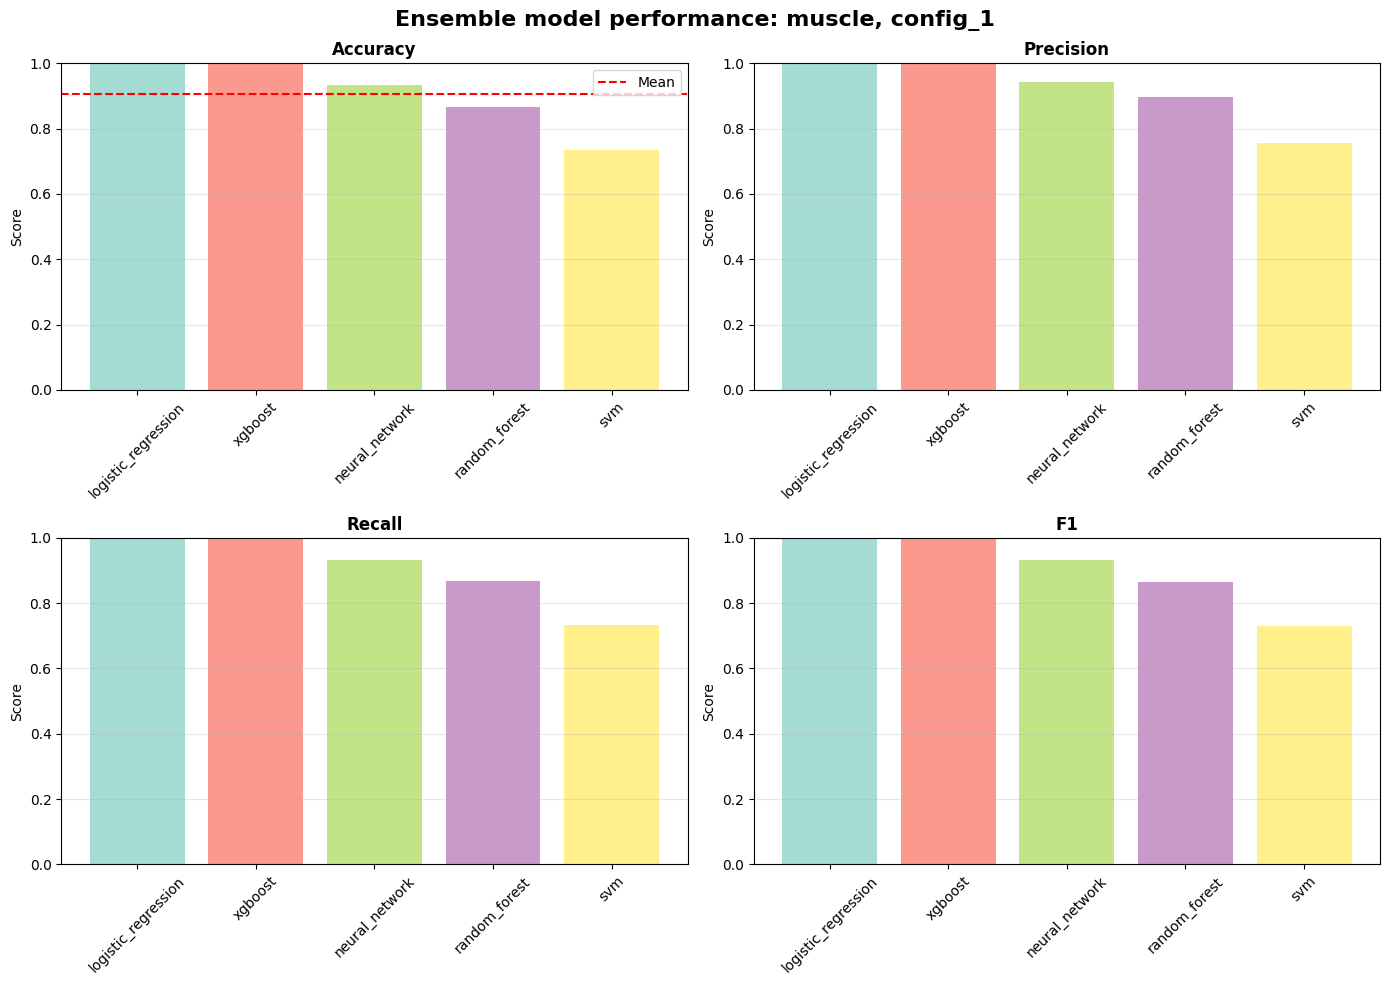

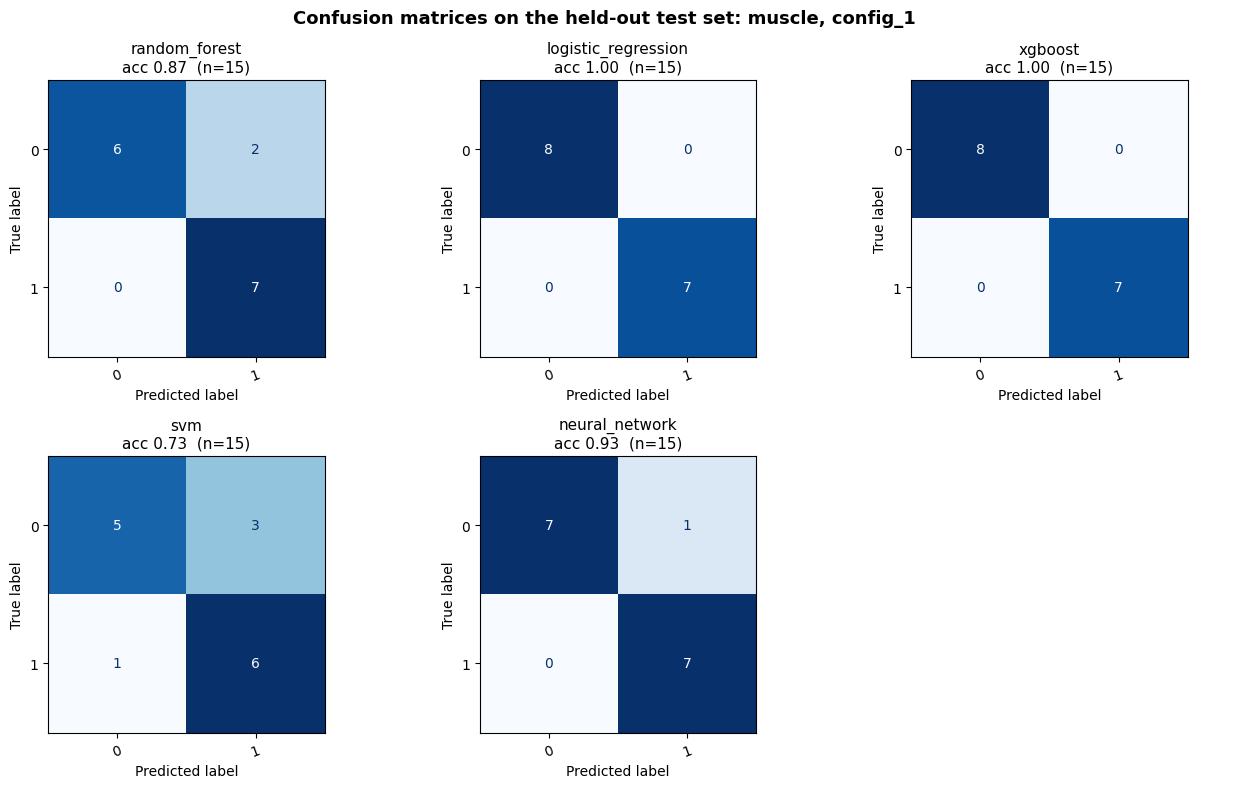

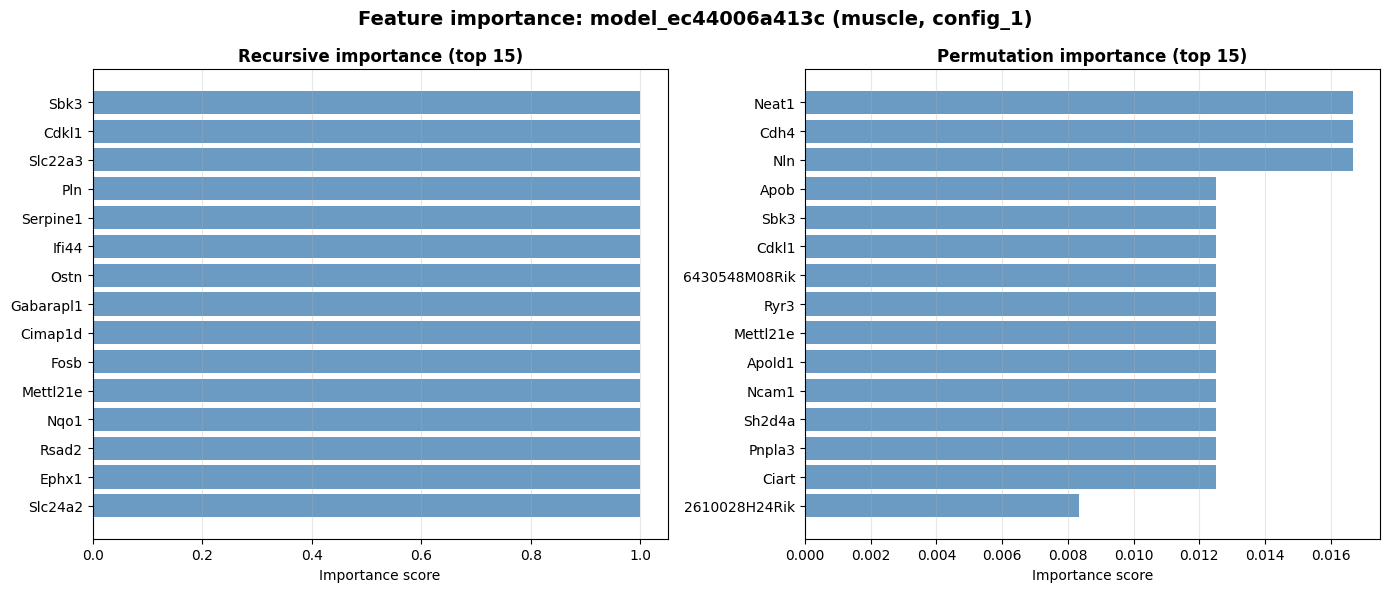

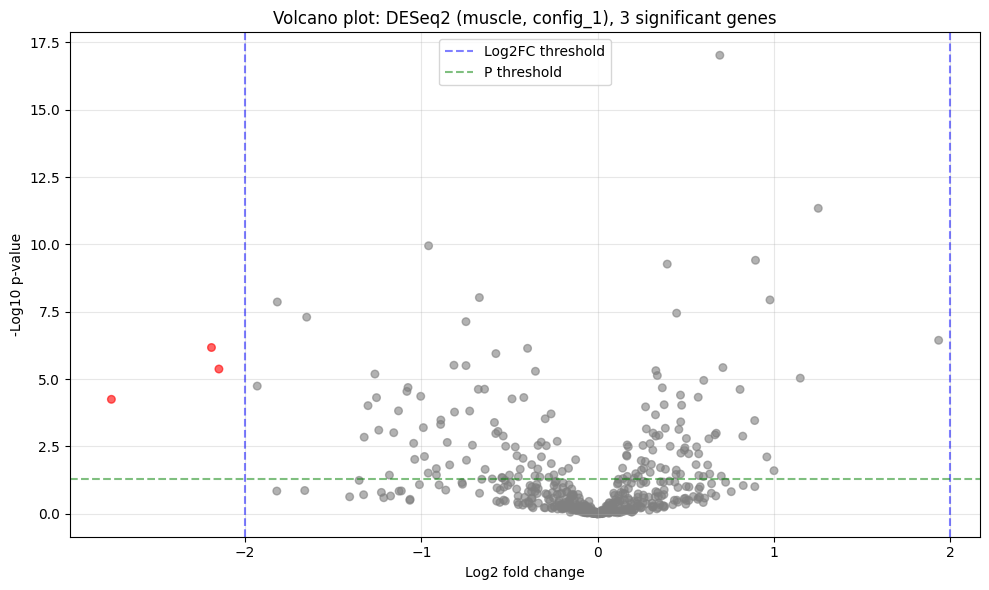

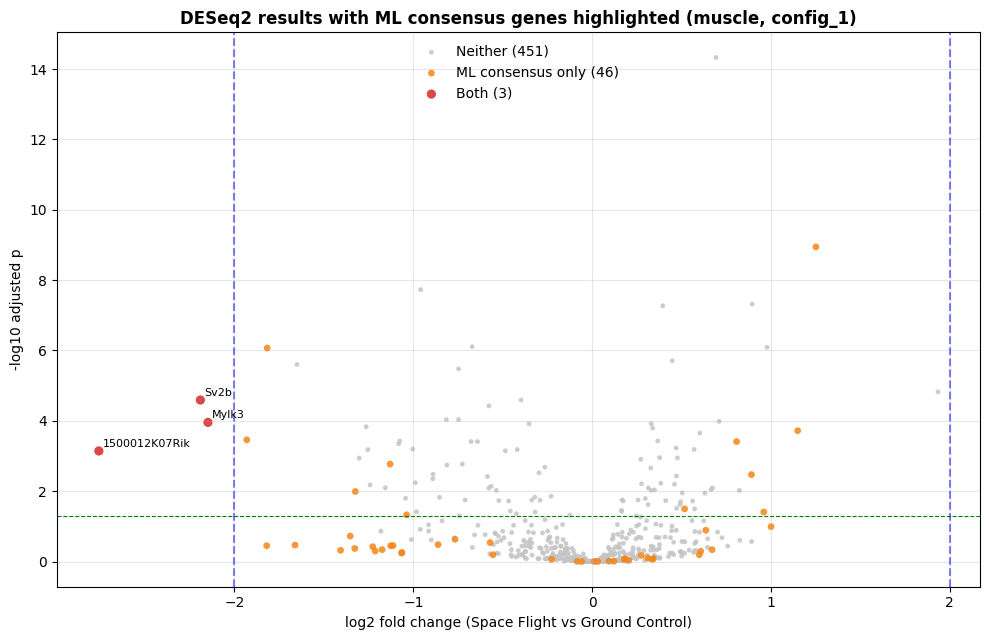

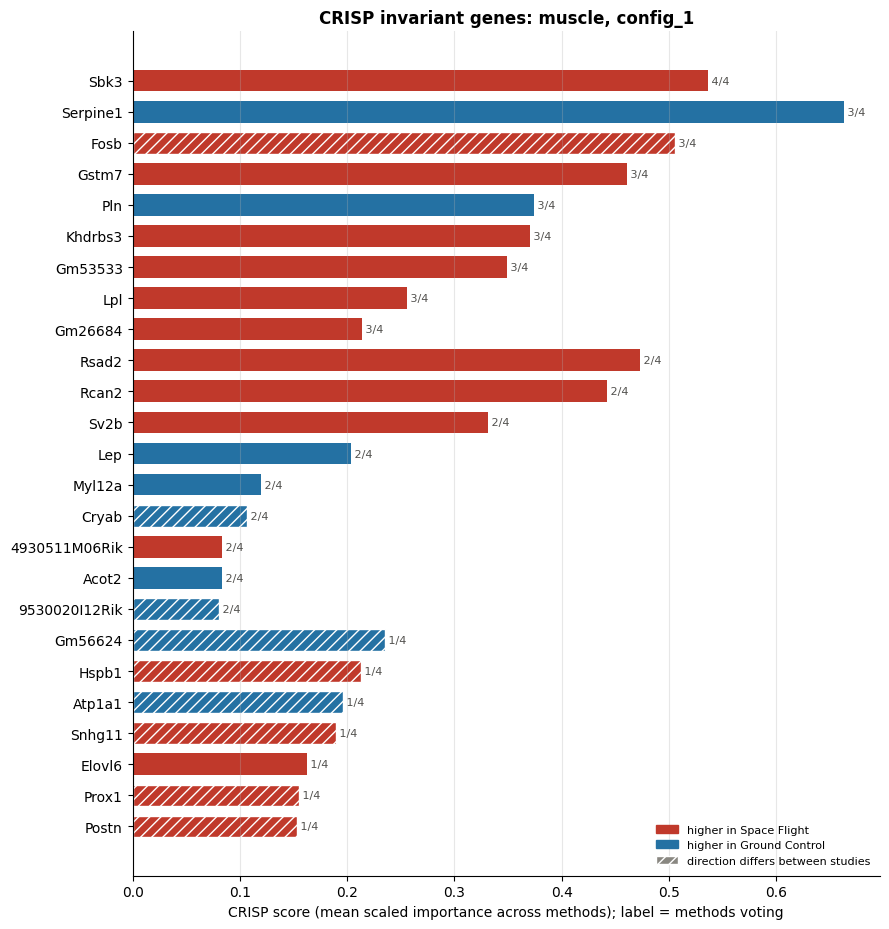

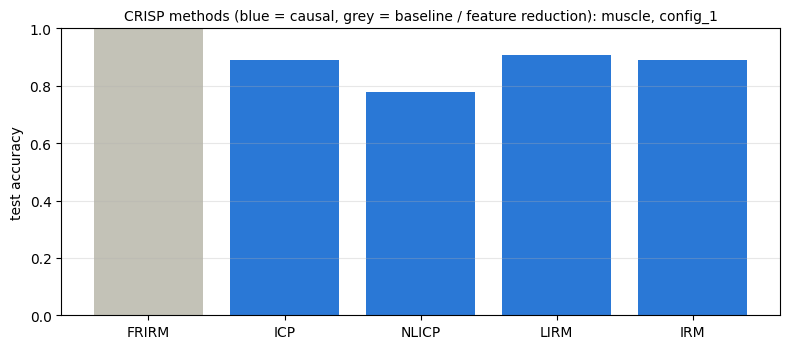

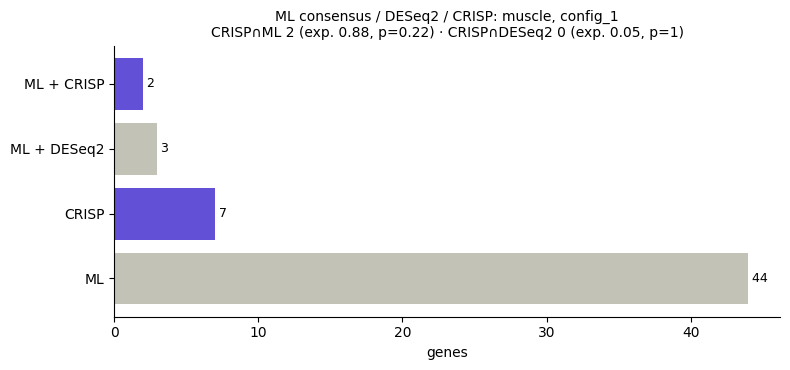

  ✓ CRISP: 9 invariant genes


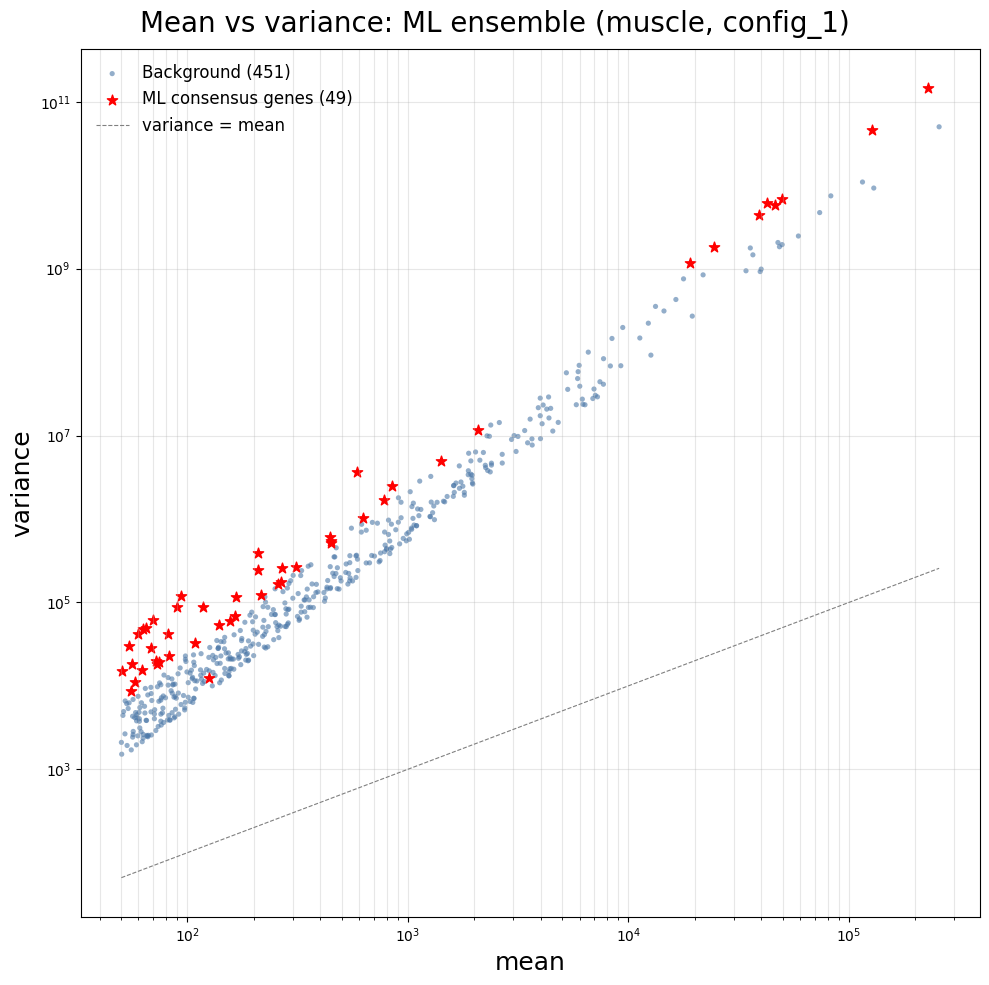

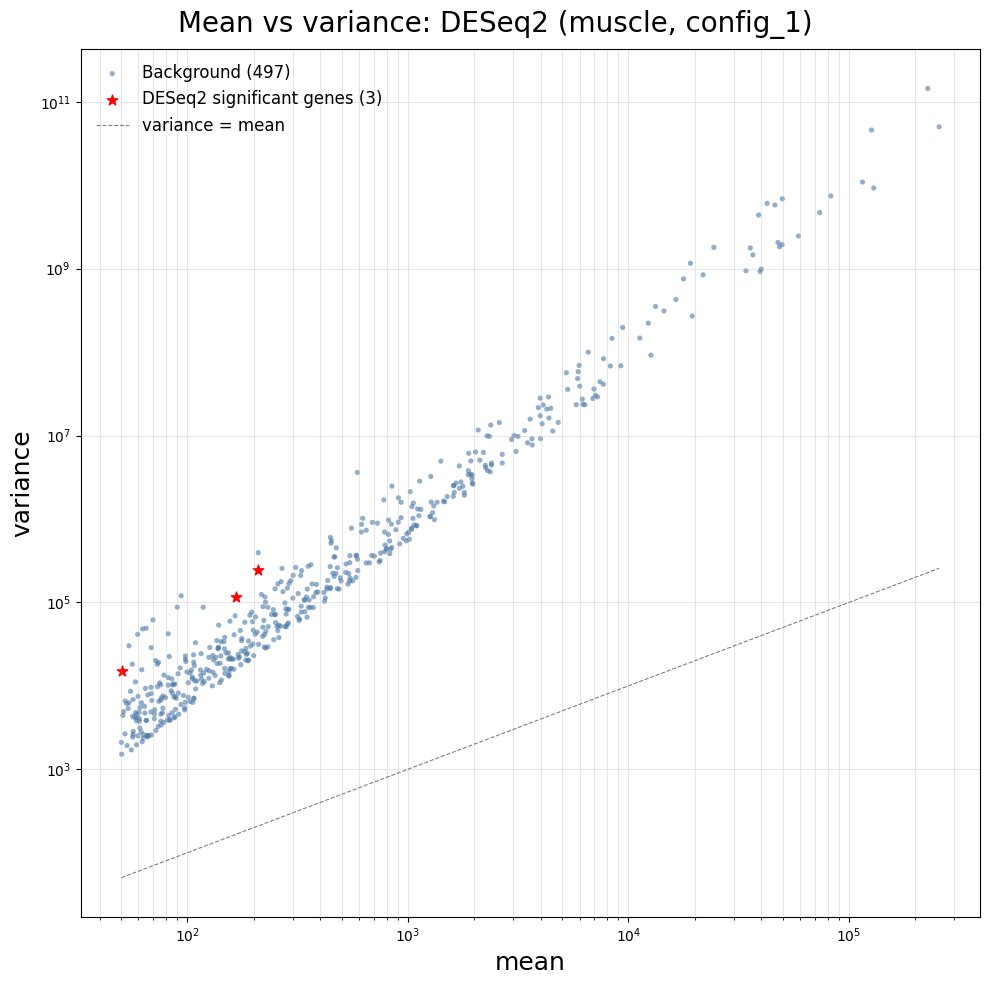

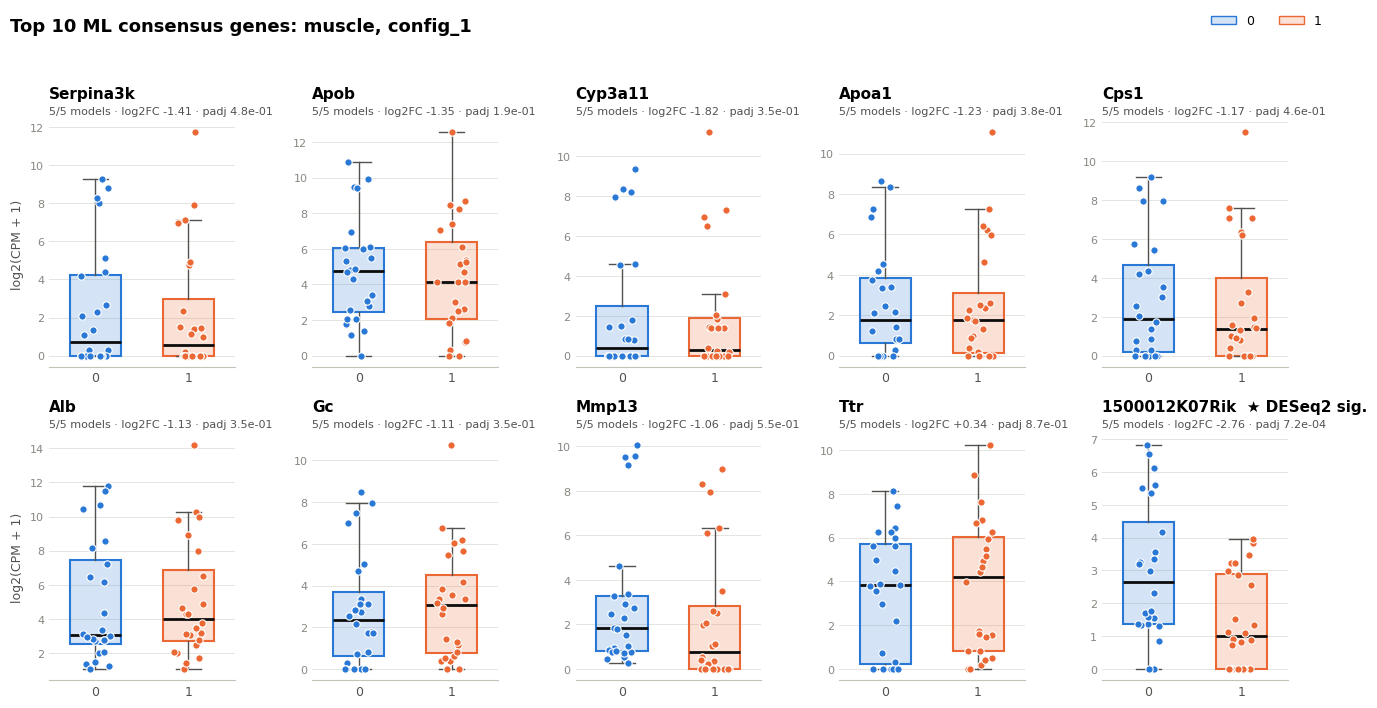

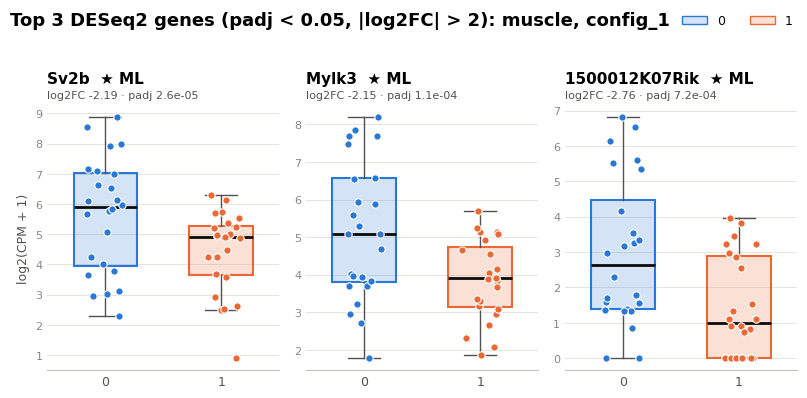

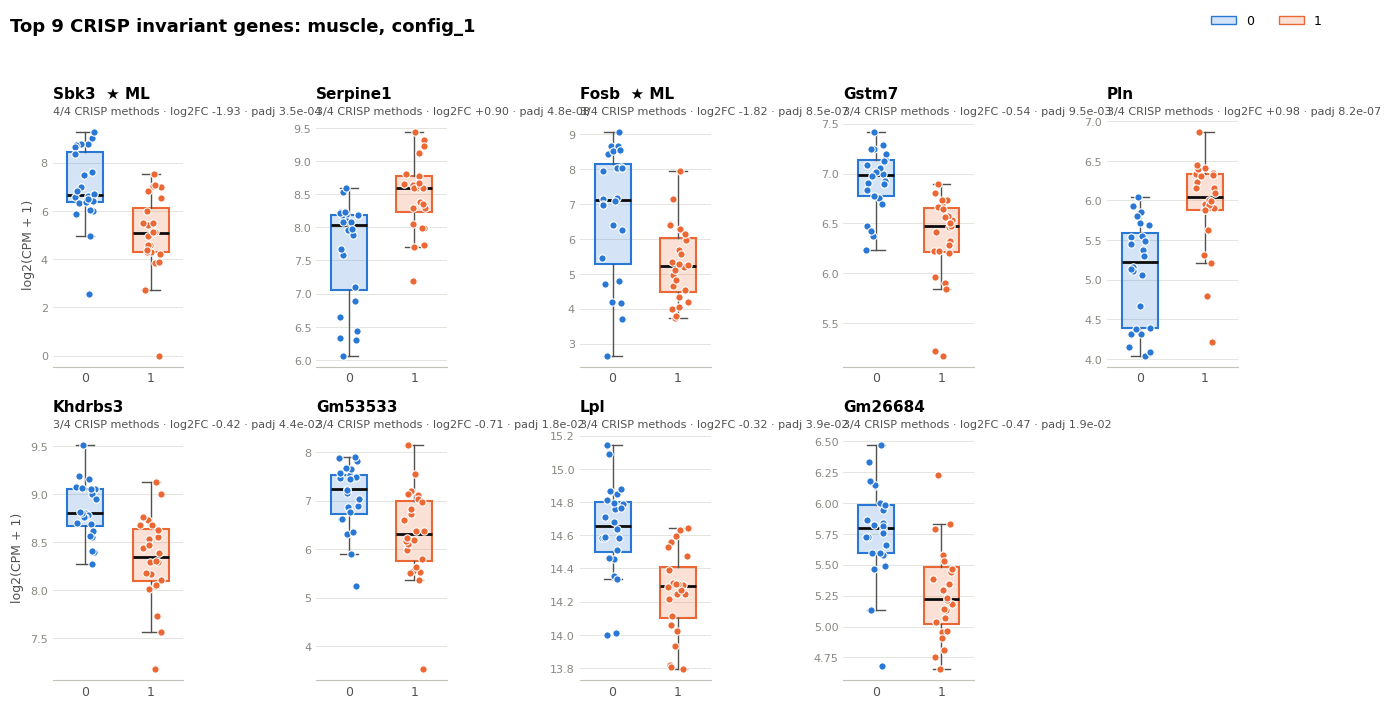

  ✓ Box plots: 21 genes
  GO BP/MF/CC/KEGG enrichment (ora, gsea) on 500 background genes. Lists: ml_consensus: 49, deseq2_significant: 3, overlap: 3. Rankings: deseq2, ml_importance.


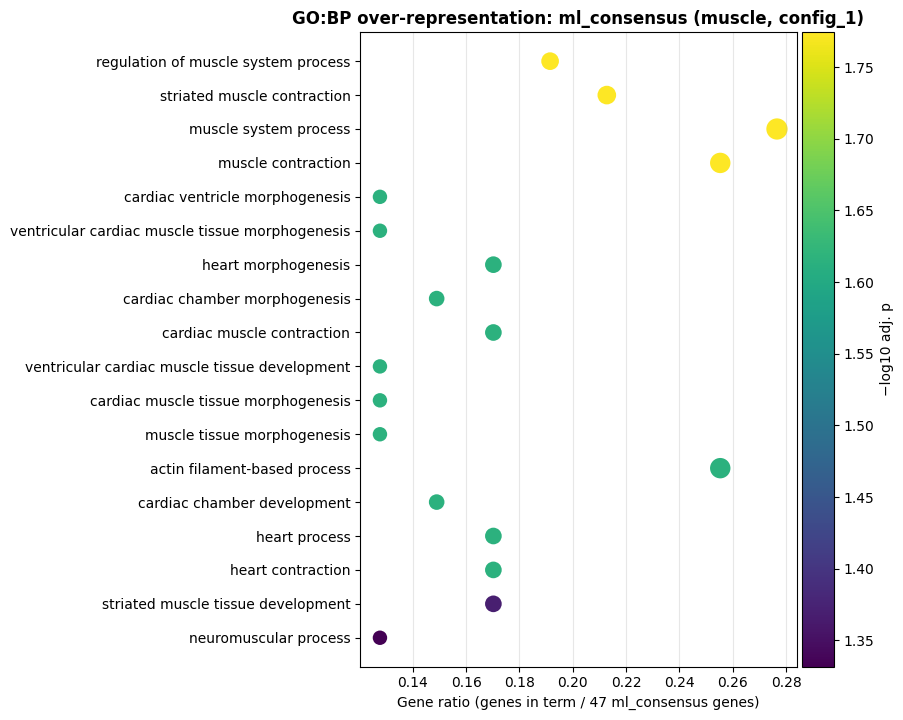

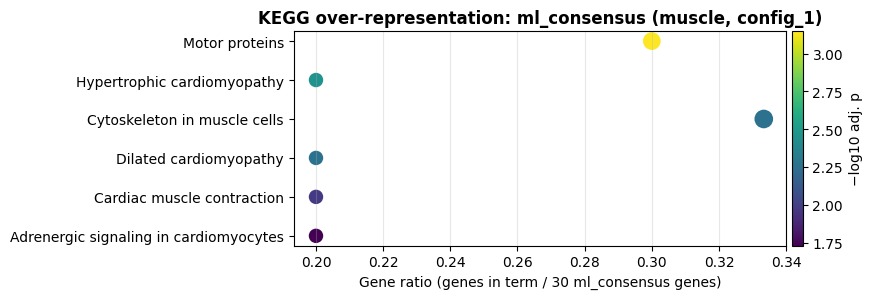

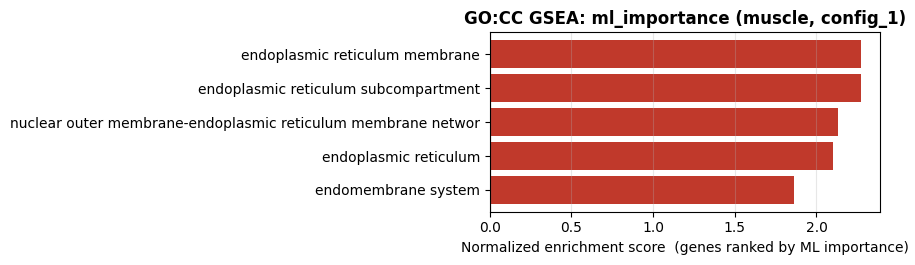

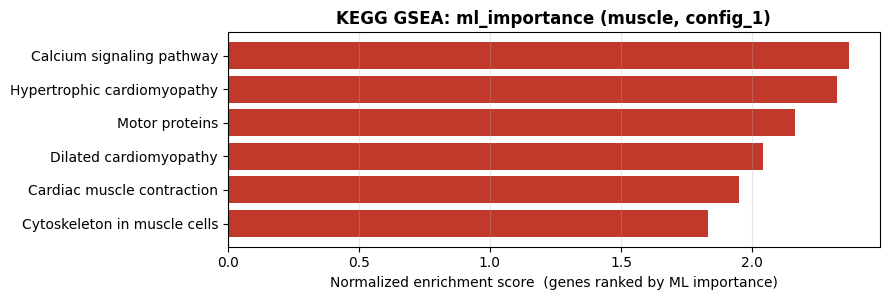

  ✓ GO enrichment: 35 terms (organism: mmu)
  → ok in 6.5 min. Consensus: 49, DESeq2 significant: 3, overlap: 3


,run,status,n_models,mean_accuracy,best_model,n_consensus_genes,deseq2_significant,overlap,crisp_genes,hypergeom_p,go_terms_ora,go_terms_gsea,minutes,errors
0,muscle_config_1,ok,5,0.9067,logistic_regression,49,3,3,9,0.00089,24,11,6.5,



Finished 1 of 1 runs without errors in 0:06:28.
Results: /content/drive/MyDrive/NASA/FM/ML_PIPELINE/20261031_205215


In [15]:
notebook_start = datetime.now()
root = make_timestamp_dir(RESUME_TIMESTAMP)
print(f"Results folder: {root}\n")

defaults = get_defaults()
plan = [(d, c) for d in DATASETS_TO_RUN for c in CONFIGS_TO_RUN]   # dataset outer: its data stays cached
write_json({"datasets": {d: DATASETS[d] for d in DATASETS_TO_RUN},
            "configs": {c: all_configs[c] for c in CONFIGS_TO_RUN},
            "backend_defaults": defaults,
            "settings": {"padj_threshold": PADJ_THRESHOLD, "log2fc_threshold": LOG2FC_THRESHOLD,
                         "top_n": TOP_N, "min_votes": MIN_VOTES, "ml_gene_set": ML_GENE_SET, "enrichment_mode": ENRICHMENT_MODE,
                         "cross_config_min_fraction": CROSS_CONFIG_MIN_FRACTION,
                         "cross_config_enrichment": CROSS_CONFIG_ENRICHMENT}},
           root / "all_configs.json")

rows, interrupted = [], False
try:
    for i, (dataset, config_name) in enumerate(plan, 1):
        run_name = f"{dataset}_{config_name}"
        prev = previous_run(root, run_name)
        if prev and prev.get("status") == "ok":
            print(f"[{i}/{len(plan)}] {run_name}: already done, skipping")
            rows.append(prev)
            continue
        print(f"\n{'=' * 80}\n[{i}/{len(plan)}] {run_name}   (OSD {DATASETS[dataset]})\n{'=' * 80}")
        rows.append(run_one(root, defaults, dataset, DATASETS[dataset], config_name, all_configs[config_name]))
        pd.DataFrame(rows).to_csv(root / "run_summary.csv", index=False)     # updated after every run
except KeyboardInterrupt:
    interrupted = True
    print(f"\nStopped. To continue later, set RESUME_TIMESTAMP = \"{root.name}\" and run all again.")

# Genes the configurations agree on, per dataset, and GO enrichment on them
cross_rows = []
if interrupted:
    print("Skipping the cross-configuration step until all runs are done.")
elif ENRICHMENT_MODE in ("cross_config", "both") or len(CONFIGS_TO_RUN) > 1:
    print(f"\n{'=' * 80}\nAcross configurations: genes found in ≥{CROSS_CONFIG_MIN_FRACTION:.0%} of runs\n{'=' * 80}")
    for dataset in DATASETS_TO_RUN:
        cross_rows.append(cross_config_analysis(root, defaults, dataset, CONFIGS_TO_RUN, CROSS_CONFIG_MIN_FRACTION,
                                                run_enrich=ENRICHMENT_MODE in ("cross_config", "both")))
    cross_summary = pd.DataFrame(cross_rows)
    cross_summary.to_csv(root / "cross_config_summary.csv", index=False)

summary = pd.DataFrame(rows)
summary.to_csv(root / "run_summary.csv", index=False)
cols = [c for c in ["run", "status", "n_models", "mean_accuracy", "best_model", "n_consensus_genes",
                    "deseq2_significant", "overlap", "crisp_genes", "crisp_ml_overlap", "crisp_deseq2_overlap", "hypergeom_p", "go_terms_ora", "go_terms_gsea",
                    "minutes", "errors"] if c in summary]
display(summary[cols])
if cross_rows:
    display(cross_summary.drop(columns=["both_genes"], errors="ignore"))

runtime = datetime.now() - notebook_start
print(f"\nFinished {sum(r.get('status') == 'ok' for r in rows)} of {len(plan)} runs without errors "
      f"in {str(runtime).split('.')[0]}.")
print(f"Results: {root}")
